# Objective 2.2
Predicting goals in a single match

We have a huge no.of columns at the start, which will be reduced to 8, these only look big these are around 12/13 features.

In [85]:
import pandas as pd
df = pd.read_csv("obj2.2.csv")
print(df.columns.to_list())

['match_no', 'fifa_match_id', 'kickoff_utc', 'stage', 'team', 'team_code', 'opponent', 'opp_code', 'team_match_no', 'goals', 'goals_90', 'went_to_et', 'knockout', 'stage_ord', 'venue', 'city', 'venue_country', 'fifa_points_own', 'fifa_points_opp', 'elo_own', 'elo_opp', 'alt_ascent_diff', 'squad_value_own', 'squad_value_opp', 'squad_age_own', 'squad_age_opp', 'home_own', 'home_opp', 'home_venue', 'rest_diff', 'tz_shift_diff', 'prior_gf', 'prior_ga', 'opp_prior_gf', 'opp_prior_ga', 'n_before', 'min90_before', 'sum_xg_before', 'sum_xga_before', 'opp_n_before', 'opp_min90_before', 'opp_sum_xg_before', 'opp_sum_xga_before']


Lets build our unbuilt features. We here are building a lagged Xg(attack) and Xga (conceed).We couldn't find Xg for last 10 competitive games, so we decided to use goals of last 10 competitve games of all qualified teams. Prior_gf is the average goals in last 10 competitive matches, prior_ga is conceeded, sum_xg_before and sum_xga_before are the Xg of last game of given team in wc.

In [86]:
first = df[df["team_match_no"] == 1]
print((first[["sum_xg_before", "min90_before"]] == 0).all())
print(df.sort_values("team_match_no").groupby("team")["sum_xg_before"]
        .apply(lambda s: s.is_monotonic_increasing).all())

sum_xg_before    True
min90_before     True
dtype: bool
True


In [87]:
played = df[df["min90_before"] > 0]    # rows that have WC data before them
print(df[["prior_gf", "prior_ga"]].describe().round(2))
print((played["sum_xg_before"] / played["min90_before"]).describe().round(2))   # observed xG per 90

       prior_gf  prior_ga
count    208.00    208.00
mean       2.12      0.79
std        0.82      0.39
min        0.80      0.00
25%        1.68      0.60
50%        1.90      0.70
75%        2.52      1.10
max        4.60      2.00
count    160.00
mean       1.42
std        0.70
min        0.07
25%        0.86
50%        1.36
75%        1.93
max        4.22
dtype: float64


In [88]:
import numpy as np
# version 1 , using raw Xg
def raw_rate(prior, s, n):
    return np.where(n == 0, prior, s / n.replace(0, np.nan))   # match 1 → prior, otherwise xG per 90

df["att_raw"]     = raw_rate(df["prior_gf"],     df["sum_xg_before"],      df["min90_before"])
df["def_raw"]     = raw_rate(df["prior_ga"],     df["sum_xga_before"],     df["min90_before"])
df["opp_att_raw"] = raw_rate(df["opp_prior_gf"], df["opp_sum_xg_before"],  df["opp_min90_before"])
df["opp_def_raw"] = raw_rate(df["opp_prior_ga"], df["opp_sum_xga_before"], df["opp_min90_before"])

print(df[["att_raw", "def_raw", "opp_att_raw", "opp_def_raw"]].describe().round(2))

       att_raw  def_raw  opp_att_raw  opp_def_raw
count   208.00   208.00       208.00       208.00
mean      1.56     1.04         1.56         1.04
std       0.77     0.63         0.77         0.63
min       0.07     0.00         0.07         0.00
25%       1.05     0.61         1.05         0.61
50%       1.55     0.88         1.55         0.88
75%       2.00     1.32         2.00         1.32
max       4.60     4.22         4.60         4.22


In [89]:
# Version 2 , shrinkage blend
#The shrinkage estimate uses the Bayesian (Gamma–Poisson) posterior-mean formula: the pre-WC rate acts as k extra games, so early estimates lean on the prior and later ones on observed WC xG.It is Bayesian-motivated only: k is not estimated by a Bayesian model but tuned by grouped cross-validation on the training set (k = 0 = raw xG, k = ∞ = prior only).

def shrink_rate(prior, s, n, k):
    if np.isinf(k):
        return prior.to_numpy()
    return np.where(n == 0, prior, (k * prior + s) / (k + n))     # blend: prior worth k games of WC data

def add_shrink(d, k):
    d = d.copy()
    d["att_shr"]     = shrink_rate(d["prior_gf"],     d["sum_xg_before"],      d["min90_before"],     k)
    d["def_shr"]     = shrink_rate(d["prior_ga"],     d["sum_xga_before"],     d["min90_before"],     k)
    d["opp_att_shr"] = shrink_rate(d["opp_prior_gf"], d["opp_sum_xg_before"],  d["opp_min90_before"], k)
    d["opp_def_shr"] = shrink_rate(d["opp_prior_ga"], d["opp_sum_xga_before"], d["opp_min90_before"], k)
    return d

# Sanity checks: both ends of k must reproduce something we already know
assert np.allclose(add_shrink(df, 0)["att_shr"], df["att_raw"])          # k = 0 → identical to Version 1
assert np.allclose(add_shrink(df, np.inf)["att_shr"], df["prior_gf"])    # k = ∞ → pure prior
print("shrinkage function worked")

shrinkage function worked


## Train/ Test split
We will be splitting at the start to prevent data leakage, grouped by match, and stratified by stage ( so every stage gets balanced distribution).

In [90]:
SEED = 2026

# Sanity check
assert df.shape == (208, 47), df.shape
assert df.isna().sum().sum() == 0, df.isna().sum()[lambda s: s > 0]
assert not df.duplicated(["match_no", "team"]).any()
assert (df["team"] != df["opponent"]).all()
assert (df.groupby("match_no").size() == 2).all()
assert ((df["stage_ord"] == 0) == (df["match_no"] <= 72)).all()
assert ((df["knockout"] == 1) == (df["match_no"] > 72)).all()


matches = df.groupby("match_no", as_index=False).first()

counts = matches["knockout"].value_counts()
print(counts)


knockout
0    72
1    32
Name: count, dtype: int64


 StratifiedGroupKfold splits the matches into 5 chunks, always keeping both rows of a match together so there’s no leakage, and gives each chunk about the same group/knockout mix.

We take the first chunk, about 21 matches, as the test set, and later reuse the same tool on the training data for cross-validation.

In [91]:
from sklearn.model_selection import StratifiedGroupKFold

sgkf = StratifiedGroupKFold(n_splits=5, random_state=SEED, shuffle=True)
train_idx, test_idx = next(sgkf.split(df, y=df['knockout'], groups=df['match_no'])) #Knockout games are smaller in counts

test_ids = np.sort(df.loc[test_idx, "match_no"].unique())
pd.DataFrame({"match_no": test_ids}).to_csv("test_match_ids.csv", index=False)

In [92]:
df["split"] = np.where(df["match_no"].isin(test_ids), "test", "train")
print(pd.crosstab(df["stage_ord"], df["split"], margins=True))
train = df[df["split"] == "train"].copy()
test  = df[df["split"] == "test"].copy()

split      test  train  All
stage_ord                  
0            30    114  144
1             6     26   32
2             4     12   16
3             0      8    8
4             0      4    4
5             2      2    4
All          42    166  208


We will properly split after making the features count 8.

a-priori baseline (domain reasoning only, defined before EDA)
Goals scored depend on own attacking strength, the opponent's defensive strength, and match context.
B2 fixes 8 features on that logic before any data exploration, so it can serve as an honest "before"
in the before/after comparison. All other candidates remain in the Phase 6 selection pool.

| Feature | Domain reasoning |
|---|---|
| elo_own, elo_opp | Overall team strength of each side (Elo outperforms FIFA ranking as a predictor) |
| att_est, opp_def_est | Own chance creation vs the opponent's tendency to concede (attack × defence logic) |
| squad_value_own, squad_value_opp (log) | Player quality of each side, independent of results history |
| home_venue | Home advantage |
| knockout | Higher stakes, expected to produce more cautious play |

This is 8 features which I think can be used as baseline, based on domain reasoning.

## Exploratory Data Analysis
Distribution, mean vs variance, Poisson curve

goals_90
0    40
1    66
2    30
3    19
4     6
5     4
7     1
Name: count, dtype: int64
mean = 1.41, variance = 1.65, var/mean = 1.17


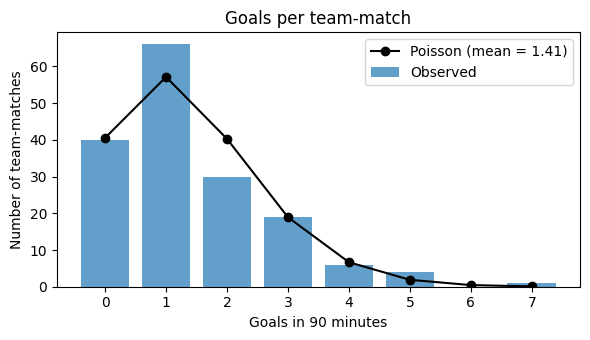

In [93]:
import matplotlib.pyplot as plt
from scipy.stats import poisson

y = train["goals_90"]
counts = y.value_counts().sort_index()
print(counts)
print(f"mean = {y.mean():.2f}, variance = {y.var():.2f}, var/mean = {y.var()/y.mean():.2f}")

k = np.arange(0, y.max() + 1)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(k, [counts.get(i, 0) for i in k], label="Observed", alpha=0.7)
ax.plot(k, poisson.pmf(k, y.mean()) * len(y), "o-", color="black",
        label=f"Poisson (mean = {y.mean():.2f})")      # pmf: probability of exactly k goals
ax.set(xlabel="Goals in 90 minutes", ylabel="Number of team-matches",
       title="Goals per team-match")
ax.legend();plt.style.use('default'); plt.tight_layout(); plt.show()

Goals per 90 is right-skewed count( mean 1.41,var 1.65). Residuals wont be normal. goals are close to random-at-a-steady-rate, with a bit more spread. The extra spread mostly comes from strong teams thrashing weak ones.

OLS assumes every feature affects goals linearly. If a relationship curves, a straight-line coefficient misrepresents. LOWESS (locally weighted scatterplot smoothing) fits many small weighted straight lines to neighbouring points (here 60% of the data each) and joins them into a curve, revealing the relationship's shape without assuming it is linear.
A straight LOWESS curve supports OLS's linearity assumption; a bend signals a transform is needed, though the curve is unreliable at the edges where few points remain.

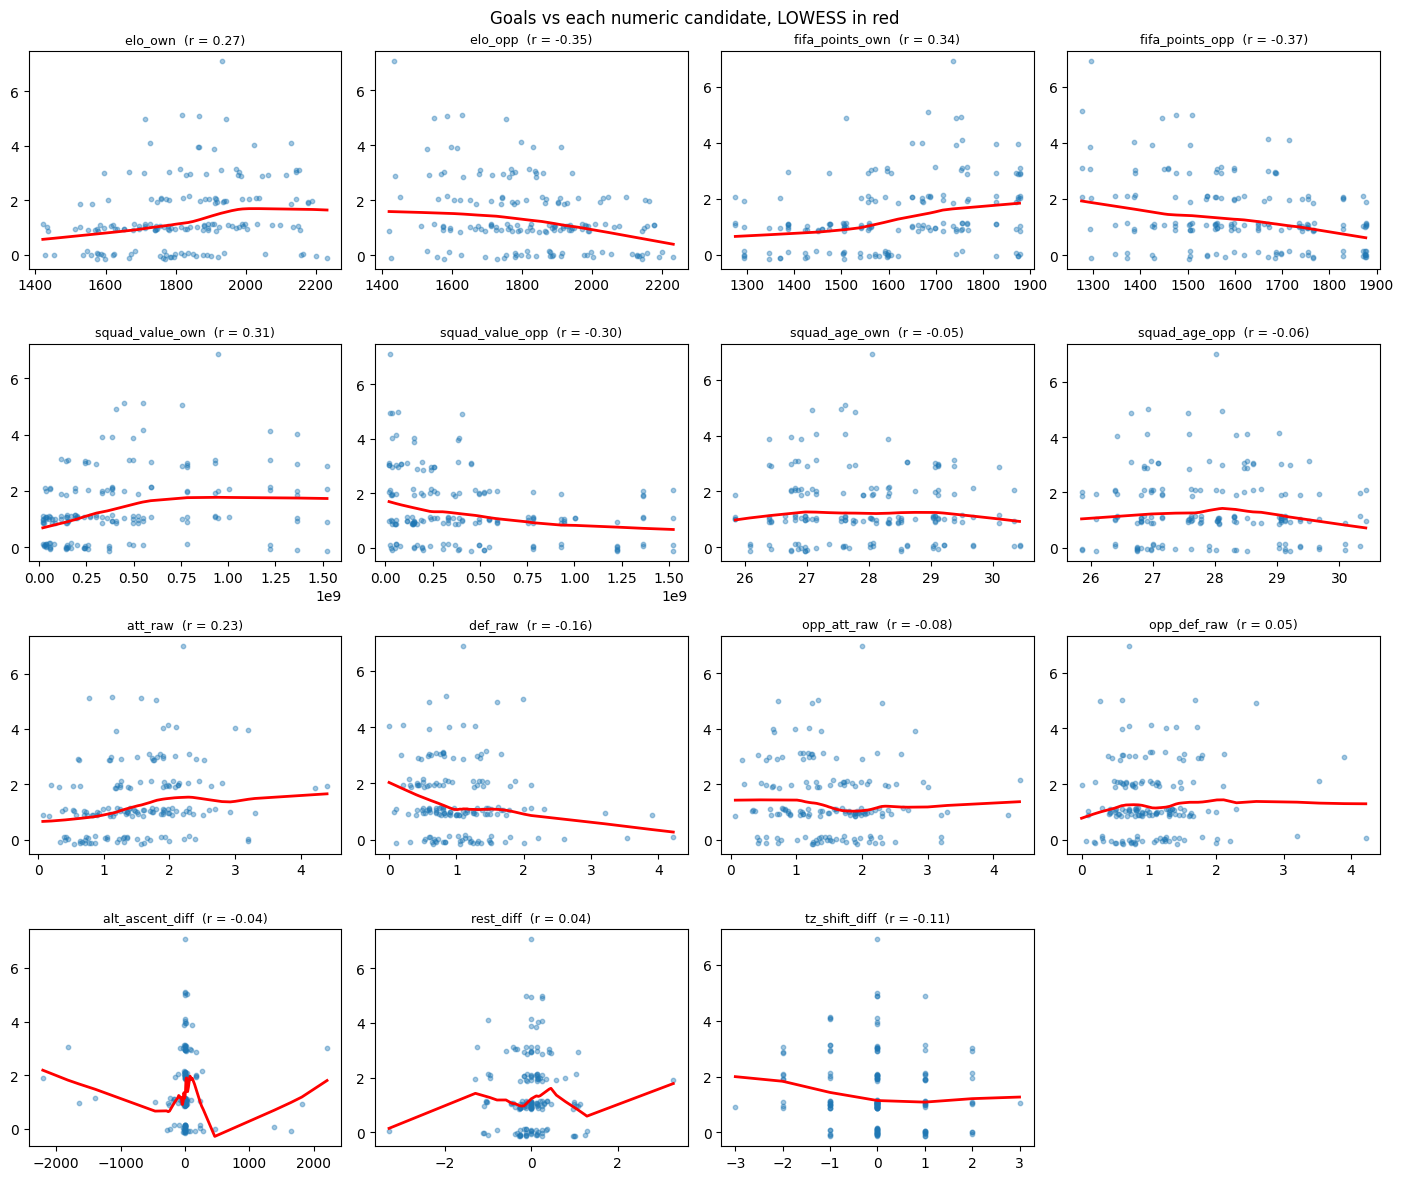

In [94]:
from statsmodels.nonparametric.smoothers_lowess import lowess

# Only continous features, features like home venue or knockout has 0 and 1
NUM = ["elo_own", "elo_opp", "fifa_points_own", "fifa_points_opp",
       "squad_value_own", "squad_value_opp", "squad_age_own", "squad_age_opp",
       "att_raw", "def_raw", "opp_att_raw", "opp_def_raw",
       "alt_ascent_diff", "rest_diff", "tz_shift_diff"]

rng_j = np.random.default_rng(SEED)
fig, axes = plt.subplots(4, 4, figsize=(14, 12))
for ax, col in zip(axes.flat, NUM):
    x, y = train[col], train["goals_90"]
    ax.scatter(x, y + rng_j.uniform(-0.15, 0.15, len(y)), s=10, alpha=0.4)
    sm = lowess(y, x, frac=0.6)               # smooth curve; frac = share of points used for each local fit
    ax.plot(sm[:, 0], sm[:, 1], color="red", lw=2)
    ax.set_title(f"{col}  (r = {x.corr(y):.2f})", fontsize=9)
axes.flat[-1].axis("off")                     # 16th panel unused
fig.suptitle("Goals vs each numeric candidate, LOWESS in red")
plt.tight_layout(); plt.show()

Strength features show roughly linear, symmetric own/opp effects (|r| 0.27–0.37; FIFA points slightly stronger than Elo), squad value is concave and right-skewed, opp_def_raw shows almost no link (r = 0.05), and squad age, altitude, rest and time-zone are near zero.
Squad value is log-transformed (concave, right-skewed), and own−opp difference encodings will be tested as strength pairs show roughly equal and opposite correlations.
Shrinkage is tested as a fix for the near-zero opp_def_raw link (r = 0.05)  and weak features (age, altitude, rest, time zone) stay as candidates for formal selection rather than being dropped by eye.

For knockout, stage_ord and the three home encodings, mean goals per group is compared with 95% confidence intervals and group sizes, the categorical counterpart of the LOWESS check.
Overlapping intervals indicate no clear difference, and groups with n < 10 are treated as uninformative.

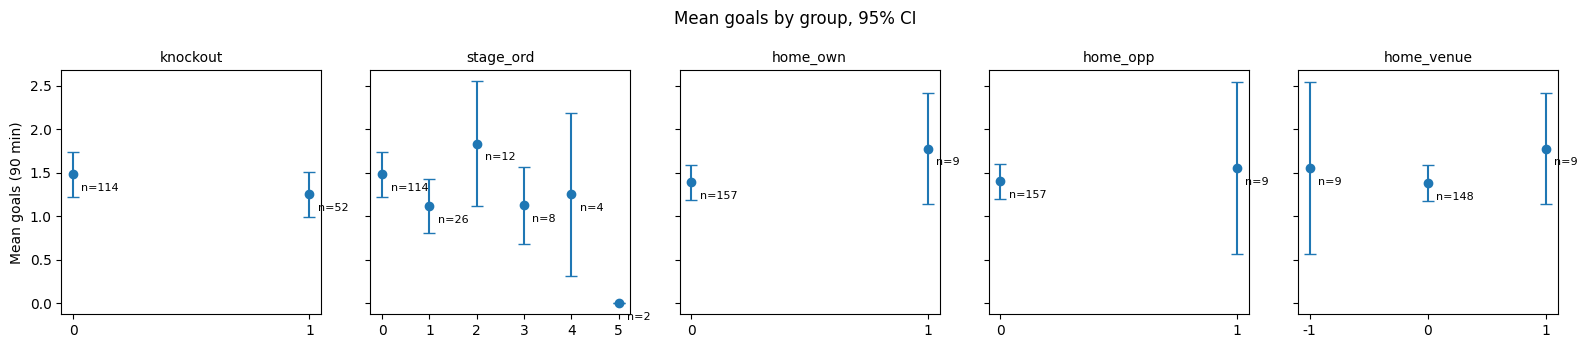

In [95]:
CAT = ["knockout", "stage_ord", "home_own", "home_opp", "home_venue"]

fig, axes = plt.subplots(1, 5, figsize=(16, 3.5), sharey=True)
for ax, col in zip(axes, CAT):
    g = train.groupby(col)["goals_90"].agg(["mean", "std", "count"])      # per-group summary
    se = g["std"] / np.sqrt(g["count"])                                    # standard error of each group mean
    ax.errorbar(g.index.astype(str), g["mean"], yerr=1.96 * se, fmt="o", capsize=4)   # mean ± 95% CI
    for x, (m, n) in enumerate(zip(g["mean"], g["count"])):
        ax.annotate(f"n={n}", (x, m), textcoords="offset points", xytext=(6, -12), fontsize=8)
    ax.set_title(col, fontsize=10)
axes[0].set_ylabel("Mean goals (90 min)")
fig.suptitle("Mean goals by group, 95% CI")
plt.tight_layout(); plt.show()

 Knockout games average fewer goals (1.25 vs 1.48) but CIs overlap; stage_ord shows no consistent trend and rounds 3–5 have n ≤ 8; home groups have only n = 9 (hosts score 1.78, their opponents 1.56), too few to estimate a home effect reliably

Does two features carry same information? If yes, OLS cant separate it and the coefficients become unstable. We use correlation heatmap to find out this answer.

Variance Inflation factor to find out how a feature is predicted by all the others combined, which correlation often misses.

In [96]:

for d in [test, train]:
    for side in ["own", "opp"]:
            d[f"log_squad_value_{side}"] = np.log(d[f"squad_value_{side}"])  # LOWESS suggests

POOL = ["elo_own", "elo_opp", "fifa_points_own", "fifa_points_opp",
        "log_squad_value_own", "log_squad_value_opp", "squad_age_own", "squad_age_opp",
        "att_raw", "def_raw", "opp_att_raw", "opp_def_raw",
        "alt_ascent_diff", "rest_diff", "tz_shift_diff", "knockout", "home_venue"]

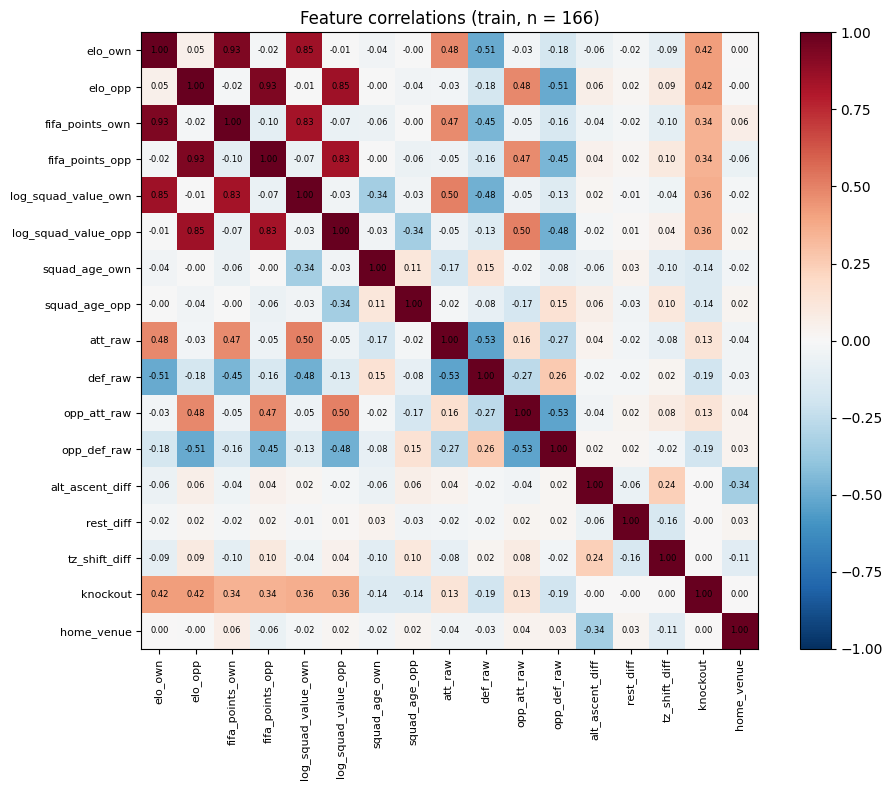

In [97]:
C = train[POOL].corr()
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(C, cmap="RdBu_r", vmin=-1, vmax=1) # red = positive, blue = negative
ax.set_xticks(range(len(POOL)), POOL, rotation=90, fontsize=8)
ax.set_yticks(range(len(POOL)), POOL, fontsize=8)
for i in range(len(POOL)):
    for j in range(len(POOL)):
        ax.text(j, i, f"{C.iloc[i, j]:.2f}", ha="center", va="center", fontsize=6)
fig.colorbar(im); ax.set_title("Feature correlations (train, n = 166)")
plt.tight_layout(); plt.show()

Elo, FIFA points and log squad value form a strength cluster within each side (r = 0.83–0.93), own and opponent features are nearly uncorrelated (|r| ≤ 0.10), knockout correlates with both Elos (0.42, stronger teams survive), and form features overlap strength only moderately (|r| ≈ 0.5).

In [98]:
#VIF
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools import add_constant
def vif_table(cols):
    X = add_constant(train[cols])                                  # VIF needs an intercept column
    return pd.Series([variance_inflation_factor(X.values, i + 1) for i in range(len(cols))],
                     index=cols).round(2).sort_values(ascending=False)   # i+1 skips the constant

print("VIF, full pool:\n", vif_table(POOL))

VIF, full pool:
 elo_own                11.67
elo_opp                11.67
fifa_points_own         8.68
fifa_points_opp         8.68
log_squad_value_own     5.98
log_squad_value_opp     5.98
def_raw                 1.83
opp_def_raw             1.83
att_raw                 1.76
opp_att_raw             1.76
squad_age_own           1.66
squad_age_opp           1.66
knockout                1.64
alt_ascent_diff         1.28
home_venue              1.25
tz_shift_diff           1.15
rest_diff               1.04
dtype: float64


With every candidate in one model, the strength measures are heavily redundant: Elo VIF 11.7 (≈91% explained by other features, SE ≈ 3.4× inflated), FIFA points 8.7 and log squad value 6.0, while all other features stay below 2. The full pool cannot be interpreted as a single OLS, so feature selection must keep at most one or two strength measures per side.

In [99]:
# a-priori baseline
B2_raw = ["elo_own", "elo_opp", "att_raw", "opp_def_raw",
          "log_squad_value_own", "log_squad_value_opp", "home_venue", "knockout"]
print("\nVIF, B2:\n", vif_table(B2_raw))


VIF, B2:
 elo_opp                4.03
elo_own                3.95
log_squad_value_own    3.82
log_squad_value_opp    3.74
opp_def_raw            1.56
knockout               1.54
att_raw                1.49
home_venue             1.01
dtype: float64


B2 is within acceptable limits (all VIF < 5), though Elo and log squad value (≈ 4, i.e. ≈75% shared information, SE ≈ 2× inflated) overlap as measures of team strength; form, knockout and home features are largely unique (VIF ≤ 1.56)

A heavily skewed feature pulls the OLS line around. The usual fix is a log.

In [100]:
NUM_SKEW = ["elo_own", "fifa_points_own", "squad_value_own", "log_squad_value_own",
            "squad_age_own", "att_raw", "def_raw",
            "alt_ascent_diff", "rest_diff", "tz_shift_diff"]  # own side only as VIF showed both values are identical

print(train[NUM_SKEW].skew().round(2).sort_values(key=abs, ascending=False))

def_raw                1.88
squad_value_own        1.17
att_raw                0.70
log_squad_value_own   -0.51
squad_age_own          0.25
fifa_points_own       -0.11
elo_own                0.04
alt_ascent_diff        0.00
rest_diff              0.00
tz_shift_diff          0.00
dtype: float64


def_raw/opp_def_raw are highly right-skewed (1.88) and squad value is skewed (1.17 → −0.51 after log); att_raw is moderate (0.70); difference features (altitude, rest, time zone) show skew 0 by construction (mirrored rows give x and −x), their issue being a spike at 0

              att_raw       def_raw      
                 mean count    mean count
team_match_no                            
1                1.97    38    0.82    38
2                1.31    38    1.21    38
3                1.11    38    1.39    38
4                1.50    26    0.95    26
5                1.72    12    0.89    12
6                1.91     8    0.83     8
7                2.00     4    0.56     4
8                1.90     2    0.41     2


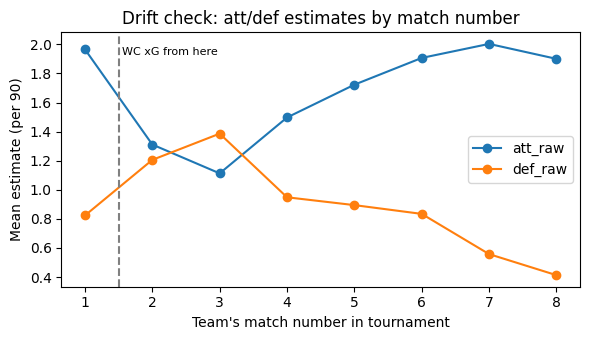

In [101]:
# Blended version of Xg, is the drift between the switch high?
d = train.groupby("team_match_no")[["att_raw", "def_raw"]].agg(["mean", "count"])
print(d.round(2))

fig, ax = plt.subplots(figsize=(6, 3.5))
for col, c in [("att_raw", "tab:blue"), ("def_raw", "tab:orange")]:
    ax.plot(d.index, d[(col, "mean")], "o-", color=c, label=col)
ax.axvline(1.5, ls="--", color="grey")                       # left: prior scale | right: WC xG scale
ax.text(1.55, ax.get_ylim()[1] * 0.95, "WC xG from here", fontsize=8, va="top")
ax.set(xlabel="Team's match number in tournament", ylabel="Mean estimate (per 90)",
       title="Drift check: att/def estimates by match number")
ax.legend(); plt.tight_layout(); plt.show()

We used average goals of last 10 competitive match for each team for their first match, but there is a huge difference between them. To minimize this, we can use a number to scale down, we will be using average goals in last two world cup. It is a limitation in our methodology, other viable options can be done in future.

In [102]:
WC_AVG = (2.64 + 2.69) / 2 / 2                        # goals per team per match, WC 2018 & 2022
first = df["team_match_no"] == 1
c_att = WC_AVG / df.loc[first, "prior_gf"].mean()
c_def = WC_AVG / df.loc[first, "prior_ga"].mean()
print(f"c_att = {c_att:.2f}, c_def = {c_def:.2f}")

for d in [train, test]:
    d["att_raw_c"]     = raw_rate(d["prior_gf"] * c_att,     d["sum_xg_before"],      d["min90_before"])
    d["def_raw_c"]     = raw_rate(d["prior_ga"] * c_def,     d["sum_xga_before"],     d["min90_before"])
    d["opp_att_raw_c"] = raw_rate(d["opp_prior_gf"] * c_att, d["opp_sum_xg_before"],  d["opp_min90_before"])
    d["opp_def_raw_c"] = raw_rate(d["opp_prior_ga"] * c_def, d["opp_sum_xga_before"], d["opp_min90_before"])
    d["first_match"]   = (d["team_match_no"] == 1).astype(int)

# Same scale fix for the blended version: if the raw prior needs rescaling, so does the prior inside the blend.
# k varies in Phase 4, so this is a function, not fixed columns. c=1 reproduces the cell-5 version.
add_shrink_v1 = add_shrink
def add_shrink(d, k, c_att=1.0, c_def=1.0):
    d = d.copy()
    d["att_shr"]     = shrink_rate(c_att * d["prior_gf"],     d["sum_xg_before"],      d["min90_before"],     k)
    d["def_shr"]     = shrink_rate(c_def * d["prior_ga"],     d["sum_xga_before"],     d["min90_before"],     k)
    d["opp_att_shr"] = shrink_rate(c_att * d["opp_prior_gf"], d["opp_sum_xg_before"],  d["opp_min90_before"], k)
    d["opp_def_shr"] = shrink_rate(c_def * d["opp_prior_ga"], d["opp_sum_xga_before"], d["opp_min90_before"], k)
    return d

c_att = 0.65, c_def = 1.66


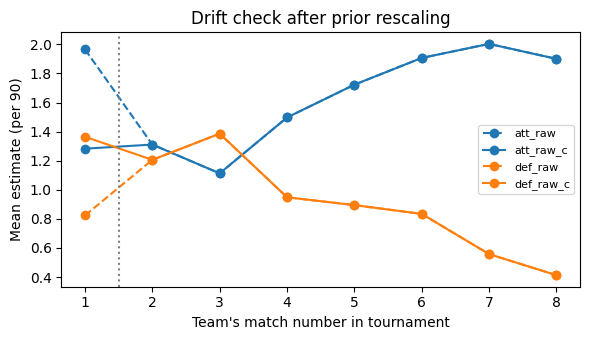

In [103]:
d = train.groupby("team_match_no")[["att_raw", "att_raw_c", "def_raw", "def_raw_c"]].mean()
fig, ax = plt.subplots(figsize=(6, 3.5))
for col, c, ls in [("att_raw", "tab:blue", "--"), ("att_raw_c", "tab:blue", "-"),
                   ("def_raw", "tab:orange", "--"), ("def_raw_c", "tab:orange", "-")]:
    ax.plot(d.index, d[col], "o", color=c, ls=ls, label=col)    # dashed = before, solid = after c fix
ax.axvline(1.5, ls=":", color="grey")
ax.set(xlabel="Team's match number in tournament", ylabel="Mean estimate (per 90)",
       title="Drift check after prior rescaling")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

The raw prior placed match-1 estimates on an inflated qualifier scale (att 1.97 vs ≈1.2 at matches 2–3; def 0.83 vs ≈1.3), a pure scale jump since matches 1–3 involve the same 48 teams; rescaling the prior by c_att = 0.65 and c_def = 1.66 (historical WC 1.33 goals per team per match ÷ mean prior of all 48 teams, leak-free) removes the jump.

OLS assumes goals rise in straight line with a feature, which LOWESS checked. Poisson assumes log(mean goals) rise in a straight line, meaning effects are multiplicative.

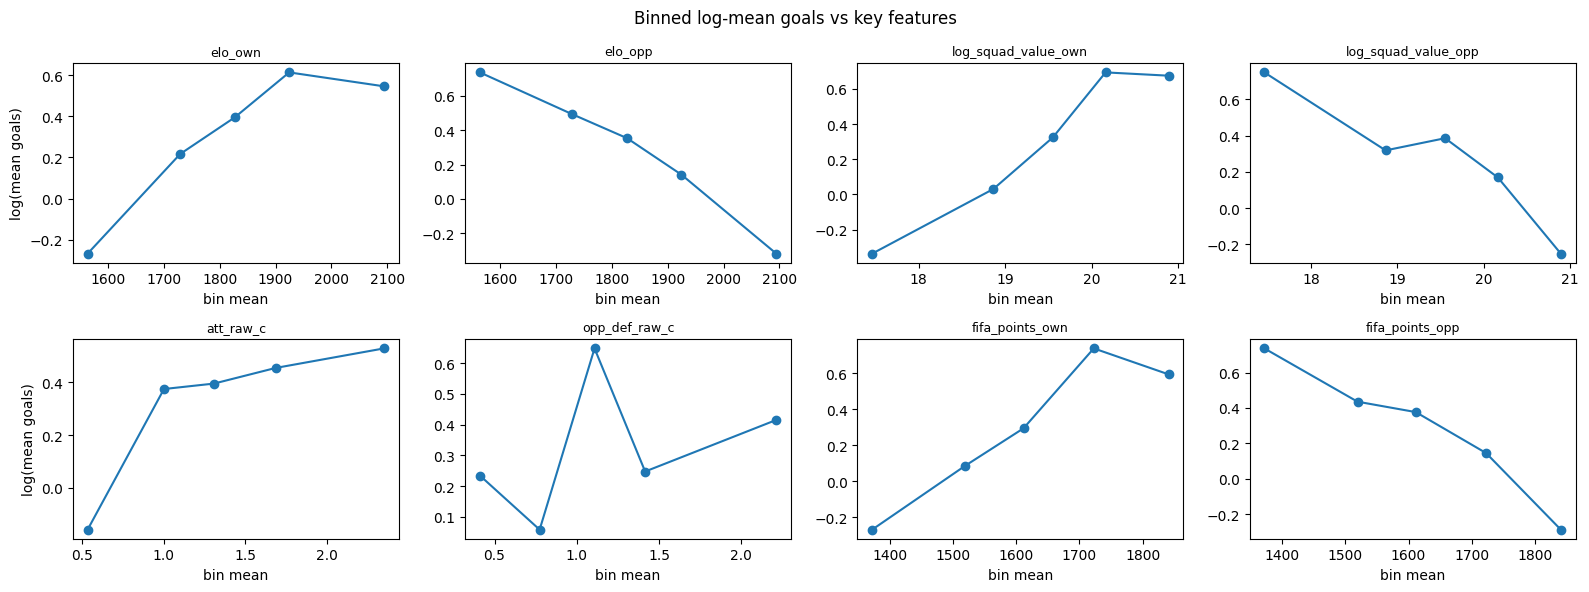

In [104]:
# Continuous B2 features (strength + form) plus FIFA points, binary and near-zero features are excluded as they have no shape to test.
KEY = ["elo_own", "elo_opp", "log_squad_value_own", "log_squad_value_opp",
       "att_raw_c", "opp_def_raw_c", "fifa_points_own", "fifa_points_opp"]

fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for ax, col in zip(axes.flat, KEY):
    bins = pd.qcut(train[col], q=5, duplicates="drop")
    g = train.groupby(bins, observed=True).agg(x=(col, "mean"), m=("goals_90", "mean"))
    ax.plot(g["x"], np.log(g["m"]), "o-")                          # straight = log-linear (Poisson shape)
    ax.set_title(col, fontsize=9); ax.set_xlabel("bin mean")
for ax in axes[:, 0]:
    ax.set_ylabel("log(mean goals)")
fig.suptitle("Binned log-mean goals vs key features")
plt.tight_layout(); plt.show()

Opponent-strength features are close to log-linear (constant percentage effect, supporting Poisson's form), own-strength features rise then plateau in the top quintile on both scales, att_raw_c is concave, and opp_def_raw_c shows no trend even after rescaling

## Feature Construction
Tuning the k-prior by grouped CV, for shrinkage based features


In [105]:
FOLDS = []      # list of (train_pos, val_pos), positional indices into train
for seed in range(10):
    sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)
    FOLDS += list(sgkf.split(train, y=train["knockout"], groups=train["match_no"]))

for tr, va in FOLDS:
    assert not set(train["match_no"].iloc[tr]) & set(train["match_no"].iloc[va])   # no match on both sides

sizes = [len(va) for _, va in FOLDS]
ko_share = [train["knockout"].iloc[va].mean() for _, va in FOLDS]
print(f"{len(FOLDS)} folds | val size {min(sizes)}–{max(sizes)} | val knockout share {min(ko_share):.2f}–{max(ko_share):.2f} "
      f"(train overall {train['knockout'].mean():.2f})")

50 folds | val size 32–34 | val knockout share 0.25–0.35 (train overall 0.31)


We can trust the folds, they are stable.

In [106]:
from sklearn.linear_model import LinearRegression
from sklearn.base import clone
# clone = fresh, unfitted copy of a model, so no fold reuses another's fit

B2 = ["elo_own", "elo_opp", "att_est", "opp_def_est",
      "log_squad_value_own", "log_squad_value_opp", "home_venue", "knockout"]

def cv_scores(d, feats, model=LinearRegression(), metric="rmse"):
    """Validation error for each of the 50 folds (same FOLDS -> paired). metric: 'rmse' (primary) or 'mae' (robustness)."""
    X, y = d[feats].to_numpy(), d["goals_90"].to_numpy()
    out = []
    for tr, va in FOLDS:
        err = y[va] - clone(model).fit(X[tr], y[tr]).predict(X[va])
        out.append(np.sqrt(np.mean(err ** 2)) if metric == "rmse" else np.mean(np.abs(err)))
    return np.array(out)
def cv_se(scores):
    """SE within each repeat (SD of its 5 folds / sqrt 5), averaged over the 10 repeats."""
    return (scores.reshape(10, 5).std(axis=1, ddof=1) / np.sqrt(5)).mean()

In [107]:
K = [0, 0.5, 1, 2, 3, 5, 10, np.inf]
VERSIONS = {"no_fix": (1.0, 1.0), "c_fix": (c_att, c_def)}

grid = {}
for name, (ca, cd) in VERSIONS.items():
    for k in K:
        d = add_shrink(train, k, ca, cd)
        d["att_est"], d["opp_def_est"] = d["att_shr"], d["opp_def_shr"]
        grid[(name, k)] = cv_scores(d, B2)

assert np.allclose(grid[("no_fix", np.inf)], grid[("c_fix", np.inf)])   # k=inf: c is a pure rescale -> identical

res = pd.DataFrame([{"version": v, "k": k, "rmse": s.mean(), "se": cv_se(s)}
                    for (v, k), s in grid.items()])
print(res.pivot(index="k", columns="version", values=["rmse", "se"]).round(4))

           rmse              se        
version   c_fix  no_fix   c_fix  no_fix
k                                      
0.0      1.1621  1.1676  0.0649  0.0642
0.5      1.1625  1.1673  0.0670  0.0659
1.0      1.1618  1.1656  0.0680  0.0667
2.0      1.1593  1.1617  0.0684  0.0670
3.0      1.1574  1.1588  0.0683  0.0670
5.0      1.1550  1.1556  0.0681  0.0670
10.0     1.1527  1.1529  0.0678  0.0671
inf      1.1504  1.1504  0.0676  0.0676


In [108]:
from scipy import stats

def paired(a, b, label):
    """a, b = 50 fold RMSEs on the same FOLDS. Positive diff = b is better (lower RMSE)."""
    diff = a - b
    J = len(diff)
    ratio = np.mean([len(va) / len(tr) for tr, va in FOLDS])          # n_val / n_train ≈ 0.25
    se_corr = np.sqrt((1 / J + ratio) * diff.var(ddof=1))             # Nadeau & Bengio corrected SE
    t = diff.mean() / se_corr
    p = 2 * stats.t.sf(abs(t), df=J - 1)                              # sf = 1 - cdf -> two-sided p-value
    print(f"{label}: mean diff {diff.mean():+.4f} | corrected SE {se_corr:.4f} | t {t:.2f} | p {p:.3f} "
          f"| b wins {np.mean(diff > 0):.0%} of folds")

paired(grid[("c_fix", 0)], grid[("c_fix", np.inf)], "k=0 vs k=inf (c_fix)")
paired(grid[("no_fix", 0)], grid[("c_fix", 0)],    "no_fix vs c_fix (k=0)")

k=0 vs k=inf (c_fix): mean diff +0.0118 | corrected SE 0.0177 | t 0.66 | p 0.510 | b wins 60% of folds
no_fix vs c_fix (k=0): mean diff +0.0055 | corrected SE 0.0089 | t 0.62 | p 0.539 | b wins 56% of folds


In [109]:
sep = {}
for ka in K:
    for kd in K:
        d = add_shrink(train, ka, c_att, c_def)
        d_def = add_shrink(train, kd, c_att, c_def)
        d["att_est"], d["opp_def_est"] = d["att_shr"], d_def["opp_def_shr"]   # att from ka, opp_def from kd
        sep[(ka, kd)] = cv_scores(d, B2)

best = min(sep, key=lambda key: sep[key].mean())          # key with the lowest mean RMSE
print("best (k_att, k_def):", best, f"RMSE {sep[best].mean():.4f}",
      f"| vs shared k=inf: {sep[best].mean() - grid[('c_fix', np.inf)].mean():+.4f}")
paired(grid[("c_fix", np.inf)], sep[best], "shared inf vs best separate")

best (k_att, k_def): (inf, 0) RMSE 1.1448 | vs shared k=inf: -0.0056
shared inf vs best separate: mean diff +0.0056 | corrected SE 0.0123 | t 0.45 | p 0.654 | b wins 74% of folds


In [110]:
for d in [train, test]:
    s = add_shrink(d, np.inf, c_att, c_def)
    d["att_est"], d["opp_def_est"] = s["att_shr"], s["opp_def_shr"]     # = c * pre-WC prior (static per team)

print(train[["att_est", "opp_def_est"]].skew().round(2))
print(train[["att_est", "opp_def_est", "elo_own", "elo_opp",
             "log_squad_value_own", "log_squad_value_opp"]].corr().round(2))
print(vif_table(B2))

att_est        1.08
opp_def_est    0.24
dtype: float64
                     att_est  opp_def_est  elo_own  elo_opp  \
att_est                 1.00        -0.07     0.34     0.04   
opp_def_est            -0.07         1.00    -0.09    -0.10   
elo_own                 0.34        -0.09     1.00     0.05   
elo_opp                 0.04        -0.10     0.05     1.00   
log_squad_value_own     0.38        -0.04     0.85    -0.01   
log_squad_value_opp     0.04        -0.10    -0.01     0.85   

                     log_squad_value_own  log_squad_value_opp  
att_est                             0.38                 0.04  
opp_def_est                        -0.04                -0.10  
elo_own                             0.85                -0.01  
elo_opp                            -0.01                 0.85  
log_squad_value_own                 1.00                -0.03  
log_squad_value_opp                -0.03                 1.00  
elo_own                3.88
elo_opp                3.84

In [111]:
DROP_V1 = ["att_raw", "def_raw", "opp_att_raw", "opp_def_raw",
           "att_raw_c", "def_raw_c", "opp_att_raw_c", "opp_def_raw_c", "first_match"]
for d in [train, test]:
    d.drop(columns=[c for c in DROP_V1 if c in d], inplace=True)   # inplace: modifies train/test directly
print("Version 1 columns dropped:", [c for c in DROP_V1 if c in train] == [])

Version 1 columns dropped: True


Grouped 10×5 CV on train (n = 166) put every k in {0 … ∞}, with and without the c fix, within 1 SE of the best RMSE. The total spread was 0.017, below the 0.02 threshold, and k = 0 vs ∞ gave corrected t = 0.66, p = 0.51. In-tournament xG therefore adds no detectable value over the pre-WC prior.
Following the pre-registered 1-SE rule, we selected **k = ∞ with the c fix**: att_est and opp_def_est are static pre-WC ratings. c is kept so the coefficients are on the World Cup scale; separate attack/defence k was not adopted (+0.0056, p = 0.65, best of 64 cells).
Checks: att_est is largely distinct from team strength (r ≈ 0.35, VIF 1.18), but opp_def_est barely tracks opponent strength (r = −0.10), likely because of confederation confounding.

## Baseline Models
Lets check if our model predicts better than a flipping a coin.

In [112]:
from sklearn.dummy import DummyRegressor

base = {
    "B0 mean": cv_scores(train, ["elo_own"], DummyRegressor(strategy="mean")),
    "B1 Elo":  cv_scores(train, ["elo_own", "elo_opp"]),
    "B2":      cv_scores(train, B2),
}
for name, s in base.items():
    print(f"{name:8s} RMSE {s.mean():.4f}  SE {cv_se(s):.4f}")

paired(base["B0 mean"], base["B1 Elo"], "B0 vs B1")
paired(base["B1 Elo"],  base["B2"],     "B1 vs B2")

B0 mean  RMSE 1.2747  SE 0.0999
B1 Elo   RMSE 1.1626  SE 0.0830
B2       RMSE 1.1504  SE 0.0676
B0 vs B1: mean diff +0.1121 | corrected SE 0.0536 | t 2.09 | p 0.042 | b wins 88% of folds
B1 vs B2: mean diff +0.0123 | corrected SE 0.0343 | t 0.36 | p 0.722 | b wins 56% of folds


Elo alone beat the mean (B0 1.275 → B1 1.163 RMSE; paired corrected t = 2.09, p = 0.042, 88% of folds), but the a-priori 8 added nothing detectable beyond Elo (B2 1.150; +0.012, p = 0.72), so every non-Elo feature must earn its place individually

## Feature Selection
We can check , rather than using elo own and opp , lets use elo diff and see if these matters, if these matters, it can free up some slots. Lets start with correlated features to reduce our vars.

In [113]:
for d in [train, test]:
    s = add_shrink(d, np.inf, c_att, c_def)                      # Version 2 (k=inf, c fix)
    d["def_est"], d["opp_att_est"] = s["def_shr"], s["opp_att_shr"]
    d["elo_diff"]  = d["elo_own"] - d["elo_opp"]
    d["fifa_diff"] = d["fifa_points_own"] - d["fifa_points_opp"]
    d["lsv_diff"]  = d["log_squad_value_own"] - d["log_squad_value_opp"]
    d["age_diff"]  = d["squad_age_own"] - d["squad_age_opp"]

assert set(train.columns) == set(test.columns), sorted(set(train.columns) ^ set(test.columns))

FULL = ["elo_own", "elo_opp", "fifa_points_own", "fifa_points_opp",
        "log_squad_value_own", "log_squad_value_opp", "squad_age_own", "squad_age_opp",
        "att_est", "def_est", "opp_att_est", "opp_def_est",
        "alt_ascent_diff", "rest_diff", "tz_shift_diff", "knockout", "home_venue"]   # 17

SWAPS = {                             # (removed, added): one swap at a time inside FULL
    "elo own/opp -> elo_diff":   (["elo_own", "elo_opp"],                         ["elo_diff"]),
    "fifa own/opp -> fifa_diff": (["fifa_points_own", "fifa_points_opp"],         ["fifa_diff"]),
    "value own/opp -> lsv_diff": (["log_squad_value_own", "log_squad_value_opp"], ["lsv_diff"]),
    "age own/opp -> age_diff":   (["squad_age_own", "squad_age_opp"],             ["age_diff"]),
    "knockout -> stage_ord":     (["knockout"],                                   ["stage_ord"]),
}

full_r, full_m = cv_scores(train, FULL), cv_scores(train, FULL, metric="mae")
print(f"FULL (17)  RMSE {full_r.mean():.4f}  SE {cv_se(full_r):.4f}  MAE {full_m.mean():.4f}\n")

rows = []
for name, (out, add) in SWAPS.items():
    feats = [c for c in FULL if c not in out] + add
    r, m = cv_scores(train, feats), cv_scores(train, feats, metric="mae")
    g = full_r - r                                               # positive = swapped-in encoding is better
    rows.append({"swap": name, "RMSE": r.mean(), "gain_RMSE": g.mean(),
                 "better_in_folds": np.mean(g > 0), "gain_MAE": (full_m - m).mean()})
print(pd.DataFrame(rows).round(4).to_string(index=False))



FULL (17)  RMSE 1.1536  SE 0.0651  MAE 0.9144

                     swap   RMSE  gain_RMSE  better_in_folds  gain_MAE
  elo own/opp -> elo_diff 1.1560    -0.0024             0.40    0.0042
fifa own/opp -> fifa_diff 1.1490     0.0046             0.44    0.0052
value own/opp -> lsv_diff 1.1450     0.0086             0.48    0.0086
  age own/opp -> age_diff 1.1363     0.0173             0.84    0.0134
    knockout -> stage_ord 1.1532     0.0003             0.52    0.0026


Starting from all 17 features (CV RMSE 1.1536 ≈ B2), every own/opp → difference swap tied or improved within the pre-registered ±0.02 (Elo −0.002, FIFA +0.005, squad value +0.009, age +0.017 in 84% of folds), so all four strength/age pairs become single differences (saving 4 slots), while stage_ord gave no gain over binary knockout (+0.0003) and knockout was kept, leaving a 13-feature encoded pool for backward elimination to 8.

## Backward elimination

In [114]:
ENC = ["elo_diff", "fifa_diff", "lsv_diff", "age_diff",
       "att_est", "def_est", "opp_att_est", "opp_def_est",
       "alt_ascent_diff", "rest_diff", "tz_shift_diff", "knockout", "home_venue"]   # 13

enc_r, enc_m = cv_scores(train, ENC), cv_scores(train, ENC, metric="mae")
print(f"ENC (13)  RMSE {enc_r.mean():.4f}  SE {cv_se(enc_r):.4f}  MAE {enc_m.mean():.4f}\n")

# Part 1: single-pass drop-one (take each feature out, measure, put it back)
rows = []
for f in ENC:
    without = [c for c in ENC if c != f]
    r, m = cv_scores(train, without), cv_scores(train, without, metric="mae")
    cost = r - enc_r   # positive = removing f hurts -> f is useful
    rows.append({"feature": f, "RMSE_without": r.mean(), "cost_RMSE": cost.mean(),
                 "hurts_in_folds": np.mean(cost > 0), "cost_MAE": (m - enc_m).mean()})
print("Drop-one (each feature removed alone, others present):")
print(pd.DataFrame(rows).sort_values("cost_RMSE", ascending=False).round(4).to_string(index=False))

# Part 2: backward elimination 13 -> 8 (re-test the remaining features after every removal)
cur, cur_r = ENC.copy(), enc_r
path = [{"n": 13, "dropped": "-", "RMSE": cur_r.mean(), "SE": cv_se(cur_r), "cost_of_drop": np.nan}]
while len(cur) > 8:
    trials = {f: cv_scores(train, [c for c in cur if c != f]) for f in cur}
    f_out = min(trials, key=lambda f: trials[f].mean())         # removal that hurts least
    path.append({"n": len(cur) - 1, "dropped": f_out, "RMSE": trials[f_out].mean(),
                 "SE": cv_se(trials[f_out]), "cost_of_drop": (trials[f_out] - cur_r).mean()})
    cur.remove(f_out); cur_r = trials[f_out]
print("\nBackward elimination path:")
print(pd.DataFrame(path).round(4).to_string(index=False))

# Part 3: guard + comparison with B2
SEL8 = cur.copy()
paired(enc_r, cur_r, "ENC(13) vs SEL8")
paired(cv_scores(train, B2), cur_r, "B2 vs SEL8")
print("\nSEL8:", SEL8)

ENC (13)  RMSE 1.1244  SE 0.0693  MAE 0.8783

Drop-one (each feature removed alone, others present):
        feature  RMSE_without  cost_RMSE  hurts_in_folds  cost_MAE
       lsv_diff        1.1589     0.0344            0.80    0.0038
        att_est        1.1553     0.0309            0.72    0.0307
       age_diff        1.1464     0.0219            0.72    0.0037
       elo_diff        1.1352     0.0108            0.80   -0.0042
      fifa_diff        1.1334     0.0090            0.76    0.0082
       knockout        1.1279     0.0034            0.66    0.0031
alt_ascent_diff        1.1244    -0.0000            0.60   -0.0013
    opp_def_est        1.1199    -0.0046            0.42   -0.0057
      rest_diff        1.1189    -0.0056            0.50   -0.0049
     home_venue        1.1185    -0.0060            0.26   -0.0034
  tz_shift_diff        1.1184    -0.0061            0.30   -0.0042
        def_est        1.1177    -0.0068            0.26   -0.0053
    opp_att_est        1.115

In single-pass drop-one, squad value (lsv_diff), pre-WC attack (att_est) and age_diff carried the most signal (removal cost +0.02 to +0.03 RMSE), while the opponent's attack, own defence, opp_def_est, home venue and time-zone shift added nothing; backward elimination removed exactly those five, leaving SEL8 = elo_diff, fifa_diff, lsv_diff, age_diff, att_est, alt_ascent_diff, rest_diff, knockout (CV RMSE 1.0925)

In [115]:
import statsmodels.api as sm
X = train[SEL8]
Z = (X - X.mean()) / X.std()                                      # standardise: coefficient = effect of +1 SD
ols   = sm.OLS(train["goals_90"], sm.add_constant(X)).fit(
            cov_type="cluster", cov_kwds={"groups": train["match_no"]})   # SEs clustered by match (rows come in pairs)
ols_z = sm.OLS(train["goals_90"], sm.add_constant(Z)).fit(
            cov_type="cluster", cov_kwds={"groups": train["match_no"]})

out = pd.DataFrame({"coef": ols.params, "coef_per_SD": ols_z.params,
                    "robust_SE_per_SD": ols_z.bse, "p": ols_z.pvalues}).drop("const")
print(out.round(4))
print("\nVIF:\n", vif_table(SEL8))
print("\nCorrelation among strength diffs:\n", train[["elo_diff", "fifa_diff", "lsv_diff"]].corr().round(2))

                   coef  coef_per_SD  robust_SE_per_SD       p
elo_diff        -0.0023      -0.5988            0.2316  0.0097
fifa_diff        0.0021       0.5078            0.2099  0.0155
lsv_diff         0.4356       0.7476            0.1906  0.0001
age_diff         0.2089       0.3147            0.0855  0.0002
att_est          0.5801       0.3063            0.0852  0.0003
alt_ascent_diff -0.0002      -0.0736            0.0282  0.0091
rest_diff        0.1105       0.0661            0.0731  0.3656
knockout        -0.3465      -0.1612            0.0835  0.0535

VIF:
 elo_diff           10.40
fifa_diff           7.99
lsv_diff            6.21
age_diff            1.55
att_est             1.20
alt_ascent_diff     1.06
knockout            1.04
rest_diff           1.02
dtype: float64

Correlation among strength diffs:
            elo_diff  fifa_diff  lsv_diff
elo_diff       1.00       0.93      0.86
fifa_diff      0.93       1.00      0.84
lsv_diff       0.86       0.84      1.00


In [116]:
for name, feats in {"drop elo":  [c for c in SEL8 if c != "elo_diff"],
                    "drop fifa": [c for c in SEL8 if c != "fifa_diff"],
                    "drop lsv":  [c for c in SEL8 if c != "lsv_diff"]}.items():
    r = cv_scores(train, feats)
    Z = (train[feats] - train[feats].mean()) / train[feats].std()
    coefs = sm.OLS(train["goals_90"], sm.add_constant(Z)).fit().params.drop("const")
    strength = {k: round(v, 3) for k, v in coefs.items() if k in ["elo_diff", "fifa_diff", "lsv_diff"]}
    print(f"{name:10s} RMSE {r.mean():.4f} | max VIF {vif_table(feats).max():.2f} | strength coefs per SD {strength}")

drop elo   RMSE 1.1056 | max VIF 4.70 | strength coefs per SD {'fifa_diff': 0.148, 'lsv_diff': 0.519}
drop fifa  RMSE 1.1046 | max VIF 5.93 | strength coefs per SD {'elo_diff': -0.201, 'lsv_diff': 0.842}
drop lsv   RMSE 1.1263 | max VIF 7.87 | strength coefs per SD {'elo_diff': -0.121, 'fifa_diff': 0.687}


The three strength differences were highly collinear (VIF up to 10.4), and elo_diff took a negative coefficient that has no football interpretation. Removing each strength measure in turn showed that only dropping Elo left positive, stable coefficients (max VIF 4.70), at a cost of 0.013 CV RMSE, below our 0.02 threshold. Elo was therefore removed, prioritising interpretability over a negligible predictive gain

Lets see if any of the feature can fill the void ..

In [117]:
SEL7 = ["fifa_diff", "lsv_diff", "age_diff", "att_est", "alt_ascent_diff", "rest_diff", "knockout"]
REMOVED = ["opp_att_est", "def_est", "tz_shift_diff", "home_venue", "opp_def_est"]

s7_r, s7_m = cv_scores(train, SEL7), cv_scores(train, SEL7, metric="mae")
print(f"SEL7  RMSE {s7_r.mean():.4f}  SE {cv_se(s7_r):.4f}  MAE {s7_m.mean():.4f}\n")

rows = []
for f in REMOVED:
    r, m = cv_scores(train, SEL7 + [f]), cv_scores(train, SEL7 + [f], metric="mae")
    d = r - s7_r                         # positive = adding f made it worse
    rows.append({"added": f, "RMSE": r.mean(), "change_RMSE": d.mean(),
                 "worse_in_folds": np.mean(d > 0), "change_MAE": (m - s7_m).mean()})
print(pd.DataFrame(rows).sort_values("change_RMSE").round(4).to_string(index=False))

SEL7  RMSE 1.1056  SE 0.0716  MAE 0.8516

        added   RMSE  change_RMSE  worse_in_folds  change_MAE
tz_shift_diff 1.1105       0.0049            0.70      0.0047
  opp_att_est 1.1108       0.0051            0.50      0.0035
  opp_def_est 1.1118       0.0061            0.68      0.0060
   home_venue 1.1121       0.0064            0.60      0.0023
      def_est 1.1121       0.0065            0.66      0.0037


In [118]:
cur = SEL7.copy(); cur_r = cv_scores(train, cur)
print(f"SEL7  RMSE {cur_r.mean():.4f}")
while len(cur) > 1:
    trials = {f: cv_scores(train, [c for c in cur if c != f]) for f in cur}
    f_out = min(trials, key=lambda f: trials[f].mean())         # removal that hurts least
    cost = (trials[f_out] - cur_r).mean()                        # positive = removal makes RMSE worse
    if cost > 0:
        print(f"stop: cheapest removal ({f_out}) would cost {cost:+.4f}")
        break
    cur.remove(f_out); cur_r = trials[f_out]
    print(f"drop {f_out:16s} cost {cost:+.4f} -> RMSE {cur_r.mean():.4f}")
FINAL = cur.copy()
print("\nFINAL:", FINAL)

SEL7  RMSE 1.1056
drop fifa_diff        cost -0.0051 -> RMSE 1.1006
drop rest_diff        cost -0.0041 -> RMSE 1.0964
drop alt_ascent_diff  cost -0.0004 -> RMSE 1.0960
stop: cheapest removal (knockout) would cost +0.0022

FINAL: ['lsv_diff', 'age_diff', 'att_est', 'knockout']


In [119]:
FINAL = ["lsv_diff", "age_diff", "att_est", "knockout"]
Z = (train[FINAL] - train[FINAL].mean()) / train[FINAL].std()
fit = sm.OLS(train["goals_90"], sm.add_constant(Z)).fit(cov_type="cluster", cov_kwds={"groups": train["match_no"]})
print(pd.DataFrame({"coef_per_SD": fit.params, "robust_SE": fit.bse, "p": fit.pvalues}).drop("const").round(4))
print("\nVIF:\n", vif_table(FINAL))

          coef_per_SD  robust_SE       p
lsv_diff       0.6565     0.0882  0.0000
age_diff       0.2752     0.0720  0.0001
att_est        0.2549     0.0822  0.0019
knockout      -0.1523     0.0820  0.0632

VIF:
 lsv_diff    1.15
age_diff    1.15
att_est     1.13
knockout    1.03
dtype: float64


 All four coefficients have the expected sign: squad-value ratio +0.66 goals per SD, age difference +0.28, pre-WC attack +0.25, knockout −0.15 (cluster-robust SEs by match; p ≤ 0.002, except knockout at 0.063). VIFs are 1.03–1.15, so each effect is interpretable on its own; the p-values are descriptive only, because the features were selected on the same data

In [120]:
SEL8  = ["elo_diff", "fifa_diff", "lsv_diff", "age_diff", "att_est", "alt_ascent_diff", "rest_diff", "knockout"]
FINAL = ["lsv_diff", "age_diff", "att_est", "knockout"]
IDS, TARGET = ["match_no", "team"], "goals_90"

full = pd.concat([train, test]).sort_values(["match_no", "team"])   # all 208 rows, in match order
assert full.shape[0] == 208 and full[IDS].duplicated().sum() == 0
assert full[SEL8 + [TARGET]].notna().all().all()

full[IDS + SEL8 + [TARGET]].to_csv("obj2_2_dataset_8.csv", index=False)    # submitted dataset: ID + exactly 8 + target
full[IDS + FINAL + [TARGET]].to_csv("obj2_2_model_4.csv", index=False)     # optimised model's features
print("saved:", full[IDS + SEL8 + [TARGET]].shape, full[IDS + FINAL + [TARGET]].shape)

saved: (208, 11) (208, 7)


## Interaction effects

In [121]:
from itertools import combinations                      # all unordered pairs, no repeats
from statsmodels.stats.multitest import multipletests  # Holm correction for many tests

FULL17 = ["elo_own", "elo_opp", "fifa_points_own", "fifa_points_opp",
          "log_squad_value_own", "log_squad_value_opp", "squad_age_own", "squad_age_opp",
          "att_est", "def_est", "opp_att_est", "opp_def_est",
          "alt_ascent_diff", "rest_diff", "tz_shift_diff", "knockout", "home_venue"]

def nb(a, b, ratio=0.25):                               # Nadeau–Bengio corrected t; positive mean = b better
    d = np.asarray(a) - np.asarray(b)
    se = np.sqrt((1/len(d) + ratio) * d.var(ddof=1))    # ratio = val/train size per fold (5-fold → 1/4)
    t = d.mean() / se
    return d.mean(), 2 * stats.t.sf(abs(t), len(d) - 1), (d > 0).mean()

X = train.copy()
final_s = cv_scores(X, FINAL)
rows = []
for a, b in combinations(FULL17, 2):
    col = f"{a}__x__{b}"
    X[col] = X[a] * X[b]
    mains = list(dict.fromkeys(FINAL + [a, b]))         # FINAL + both main effects, duplicates removed
    s_int = cv_scores(X, mains + [col])
    gain, p, win = nb(cv_scores(X, mains), s_int)
    rows.append((a, b, gain, p, win, nb(final_s, s_int)[0]))
    X.drop(columns=col, inplace=True)

res = pd.DataFrame(rows, columns=["a", "b", "gain_vs_mains", "p", "win", "gain_vs_FINAL"])
res["p_holm"] = multipletests(res["p"], method="holm")[1]
print("raw p<0.05:", (res.p < .05).sum(), "| Holm p<0.05:", (res.p_holm < .05).sum())
res.sort_values("gain_vs_mains", ascending=False).head(10)

raw p<0.05: 0 | Holm p<0.05: 0


,a,b,gain_vs_mains,p,win,gain_vs_FINAL,p_holm
71,log_squad_value_opp,squad_age_opp,0.020954,0.415338,0.74,0.003306,1.0
107,att_est,home_venue,0.016297,0.316398,0.72,0.011260,1.0
24,elo_opp,opp_att_est,0.016138,0.440008,0.66,0.006900,1.0
115,opp_att_est,opp_def_est,0.014973,0.401509,0.74,0.004174,1.0
125,opp_def_est,home_venue,0.010853,0.257951,0.74,-0.000828,1.0
74,log_squad_value_opp,opp_att_est,0.009767,0.678154,0.68,-0.000161,1.0
93,squad_age_opp,opp_att_est,0.009406,0.517713,0.68,-0.009286,1.0
119,opp_att_est,knockout,0.007536,0.408511,0.66,0.003188,1.0
35,fifa_points_own,squad_age_opp,0.006965,0.548365,0.72,-0.010465,1.0
85,squad_age_own,opp_def_est,0.005391,0.654341,0.66,-0.012047,1.0


All 136 pairwise interactions among the 17 candidates were screened against their main-effects-only models (single-level CV, Holm-corrected). None survived correction (all adjusted p = 1.0), and none improved on FINAL by the 0.02 threshold (best ΔRMSE 0.011), so no interaction was added.

## Nested CV
We did most of our feature selection inside same folds , which may have increased model's optimism from small to substantial. Lets check.

In [122]:
DIFF_SWAPS = {"elo":  (["elo_own", "elo_opp"],                         ["elo_diff"]),
              "fifa": (["fifa_points_own", "fifa_points_opp"],         ["fifa_diff"]),
              "lsv":  (["log_squad_value_own", "log_squad_value_opp"], ["lsv_diff"]),
              "age":  (["squad_age_own", "squad_age_opp"],             ["age_diff"])}
STRENGTH = {"elo": {"elo_diff": 1, "elo_own": 1, "elo_opp": -1}, # expected sign of each column
            "fifa": {"fifa_diff": 1, "fifa_points_own": 1, "fifa_points_opp": -1},
            "lsv": {"lsv_diff": 1, "log_squad_value_own": 1, "log_squad_value_opp": -1}}

def cv_f(d, feats, folds):
    """Fold RMSEs for OLS on d[feats]; folds are positional indices into d."""
    X, y = d[feats].to_numpy(), d["goals_90"].to_numpy()
    return np.array([np.sqrt(np.mean((y[va] - LinearRegression().fit(X[tr], y[tr]).predict(X[va])) ** 2))
                     for tr, va in folds])

def strength_ok(d, feats):
    """Collinearity rule: every strength coefficient has its expected sign AND max VIF <= 5."""
    Z = (d[feats] - d[feats].mean()) / d[feats].std()
    coef = dict(zip(feats, LinearRegression().fit(Z, d["goals_90"]).coef_))
    signs_ok = all(np.sign(coef[c]) == s for g in STRENGTH.values() for c, s in g.items() if c in feats)
    X = add_constant(d[feats]).values
    vif_max = max(variance_inflation_factor(X, i + 1) for i in range(len(feats)))
    return signs_ok and vif_max <= 5

def select_features(d, folds, verbose=False):
    # 1. encodings inside the full 17 (pre-registered ±0.02 rules)
    feats, base = FULL17.copy(), cv_f(d, FULL17, folds)
    for name, (out, add) in DIFF_SWAPS.items():
        trial = [c for c in FULL17 if c not in out] + add
        if (base - cv_f(d, trial, folds)).mean() >= -0.02:                 # diff not worse by > 0.02 -> use diff
            feats = [c for c in feats if c not in out] + add
    if (base - cv_f(d, [c for c in FULL17 if c != "knockout"] + ["stage_ord"], folds)).mean() >= 0.02:
        feats = [c for c in feats if c != "knockout"] + ["stage_ord"]

    # 2. backward elimination to 8 (remove the least harmful each round)
    while len(feats) > 8:
        trials = {f: cv_f(d, [c for c in feats if c != f], folds).mean() for f in feats}
        feats.remove(min(trials, key=trials.get))
    sel8 = feats.copy()

    # 3. collinearity rule: drop the strength measure whose removal passes the rule (lowest RMSE among passers)
    while not strength_ok(d, feats):
        groups = [g for g, cols in STRENGTH.items() if any(c in feats for c in cols)]
        options = {g: [c for c in feats if c not in STRENGTH[g]] for g in groups}
        passing = {g: o for g, o in options.items() if strength_ok(d, o)}
        pool = passing if passing else options                            # fallback: best RMSE if none passes
        g_out = min(pool, key=lambda g: cv_f(d, pool[g], folds).mean())
        feats = pool[g_out]

    # 4. stopping-rule elimination: remove while removal does not worsen mean RMSE
    cur_r = cv_f(d, feats, folds).mean()
    while len(feats) > 1:
        trials = {f: cv_f(d, [c for c in feats if c != f], folds).mean() for f in feats}
        f_out = min(trials, key=trials.get)
        if trials[f_out] - cur_r > 0:
            break
        feats.remove(f_out); cur_r = trials[f_out]
    if verbose:
        print("SEL8:", sel8, "\nFINAL:", feats)
    return feats, sel8

# Sanity check: on the full train with our 50 folds, the automated rules must reproduce the manual result
auto_final, auto_sel8 = select_features(train, FOLDS, verbose=True)
print("matches manual FINAL:", set(auto_final) == set(FINAL), "| matches manual SEL8:", set(auto_sel8) == set(SEL8))

SEL8: ['att_est', 'alt_ascent_diff', 'rest_diff', 'knockout', 'elo_diff', 'fifa_diff', 'lsv_diff', 'age_diff'] 
FINAL: ['att_est', 'knockout', 'lsv_diff', 'age_diff']
matches manual FINAL: True | matches manual SEL8: True


In [123]:
def make_folds(d, n_rep, seed0):
    """Repeated StratifiedGroupKFold on d (positional indices), grouped by match, stratified by knockout."""
    folds = []
    for s in range(seed0, seed0 + n_rep):
        sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=s)
        folds += list(sgkf.split(d, y=d["knockout"], groups=d["match_no"]))
    return folds

def rmse_fit(d_tr, d_va, feats):
    """Fit OLS on d_tr[feats], RMSE on d_va (feats=[] -> predict the training mean, i.e. B0)."""
    if not feats:
        pred = np.full(len(d_va), d_tr["goals_90"].mean())
    else:
        pred = LinearRegression().fit(d_tr[feats], d_tr["goals_90"]).predict(d_va[feats])
    return np.sqrt(np.mean((d_va["goals_90"].to_numpy() - pred) ** 2))

OUTER = make_folds(train, n_rep=2, seed0=100)        # 10 outer splits; seeds differ from FOLDS (0-9)
nest = []
for i, (o_tr, o_va) in enumerate(OUTER):
    d_tr, d_va = train.iloc[o_tr], train.iloc[o_va]
    inner = make_folds(d_tr, n_rep=2, seed0=200 + i)   # inner folds built ONLY from outer-train rows
    chosen, chosen8 = select_features(d_tr, inner)
    nest.append({"fold": i,
                 "procedure": rmse_fit(d_tr, d_va, chosen),
                 "B2": rmse_fit(d_tr, d_va, B2),
                 "B1": rmse_fit(d_tr, d_va, ["elo_own", "elo_opp"]),
                 "B0": rmse_fit(d_tr, d_va, []),
                 "FINAL_fixed": rmse_fit(d_tr, d_va, FINAL),       # reference only: chosen using these rows
                 "n_chosen": len(chosen), "chosen": chosen, "chosen8": chosen8})
    print(f"outer {i}: procedure {nest[-1]['procedure']:.4f} | B2 {nest[-1]['B2']:.4f} | chose {chosen}")
nest = pd.DataFrame(nest)

outer 0: procedure 0.9798 | B2 0.9893 | chose ['att_est', 'rest_diff', 'knockout', 'home_venue', 'lsv_diff', 'age_diff']
outer 1: procedure 1.2023 | B2 1.1663 | chose ['att_est', 'alt_ascent_diff', 'knockout', 'fifa_diff', 'age_diff']
outer 2: procedure 1.3866 | B2 1.4113 | chose ['att_est', 'alt_ascent_diff', 'lsv_diff', 'age_diff']
outer 3: procedure 1.1887 | B2 1.0917 | chose ['att_est', 'fifa_diff', 'age_diff']
outer 4: procedure 1.0488 | B2 0.9651 | chose ['att_est', 'opp_att_est', 'alt_ascent_diff', 'lsv_diff', 'age_diff']
outer 5: procedure 1.0739 | B2 1.0664 | chose ['att_est', 'def_est', 'lsv_diff', 'age_diff']
outer 6: procedure 0.9639 | B2 1.1136 | chose ['att_est', 'alt_ascent_diff', 'lsv_diff', 'age_diff']
outer 7: procedure 1.4894 | B2 1.5047 | chose ['att_est', 'knockout', 'lsv_diff', 'age_diff']
outer 8: procedure 1.0335 | B2 1.0468 | chose ['att_est', 'alt_ascent_diff', 'lsv_diff', 'age_diff']
outer 9: procedure 0.9408 | B2 0.9667 | chose ['log_squad_value_own', 'log_s

In [124]:
print(nest[["procedure", "B2", "B1", "B0", "FINAL_fixed"]].agg(["mean", "std"]).round(4))
for other in ["B2", "B1", "B0"]:
    d = nest[other] - nest["procedure"]                               # positive = procedure better
    print(f"procedure vs {other}: mean diff {d.mean():+.4f} | procedure better in {np.mean(d > 0):.0%} of outer folds")

counts = pd.Series([f for ch in nest["chosen"] for f in ch]).value_counts()
print("\nSelection frequency (out of 10):\n", counts)
print("\nModel size per fold:", nest["n_chosen"].tolist())

      procedure      B2      B1      B0  FINAL_fixed
mean     1.1308  1.1322  1.1374  1.2624       1.0814
std      0.1852  0.1847  0.2352  0.2587       0.1938
procedure vs B2: mean diff +0.0014 | procedure better in 60% of outer folds
procedure vs B1: mean diff +0.0066 | procedure better in 50% of outer folds
procedure vs B0: mean diff +0.1317 | procedure better in 80% of outer folds

Selection frequency (out of 10):
 att_est                10
age_diff               10
lsv_diff                7
alt_ascent_diff         5
knockout                4
home_venue              2
fifa_diff               2
rest_diff               1
opp_att_est             1
def_est                 1
log_squad_value_own     1
log_squad_value_opp     1
Name: count, dtype: int64

Model size per fold: [6, 5, 4, 3, 5, 4, 4, 4, 4, 6]


Re-running the whole selection procedure inside 10 outer folds gave RMSE 1.131 on unseen matches — tied with B2 (1.132) and Elo-only B1 (1.137), clearly better than the mean (1.262) — so the earlier single-level score (1.081) was ~0.05 optimistic and selection did not improve accuracy.
Its value is simplicity and stability: att_est and age_diff were chosen in 10/10 folds and a squad-value strength measure in 7/10, so the 4-feature FINAL model (lsv_diff, att_est, age_diff, knockout) is kept for interpretability at equal accuracy, with knockout flagged as unstable (4/10).

## Competing algorithms
OLS may predict negative values, but poisson doesn't and for goals it may be better. It assumes mean = variance and effects are multplicative

In [125]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import PoissonRegressor

pois = make_pipeline(StandardScaler(), PoissonRegressor(alpha=0, max_iter=1000))
# alpha=0 is essential: sklearn's default alpha=1.0 silently adds an L2 penalty (that'd be a ridge-Poisson)

ols_s  = cv_scores(train, FINAL)
pois_s = cv_scores(train, FINAL, model=pois)
paired(ols_s, pois_s, "FINAL: OLS vs Poisson")

print("min OLS fitted value:", LinearRegression().fit(train[FINAL], train["goals_90"]).predict(train[FINAL]).min().round(3))

FINAL: OLS vs Poisson: mean diff +0.0205 | corrected SE 0.0255 | t 0.80 | p 0.427 | b wins 70% of folds
min OLS fitted value: -0.189


In [126]:
pois_mae = cv_scores(train, FINAL, model=pois, metric="mae")
paired(cv_scores(train, FINAL, metric="mae"), pois_mae, "MAE: OLS vs Poisson")

ols_fit = LinearRegression().fit(train[FINAL], train["goals_90"]).predict(train[FINAL])
print("OLS negative predictions:", (ols_fit < 0).sum(), "of", len(ols_fit))

pfit = pois.fit(train[FINAL], train["goals_90"]); mu = pfit.predict(train[FINAL])
print("Pearson dispersion:", round((((train["goals_90"] - mu)**2 / mu).sum() / (len(mu) - len(FINAL) - 1)), 3))

MAE: OLS vs Poisson: mean diff +0.0141 | corrected SE 0.0214 | t 0.66 | p 0.513 | b wins 68% of folds
OLS negative predictions: 3 of 166
Pearson dispersion: 0.744


In [127]:
print(train["goals_90"].mean().round(3), train["goals_90"].var().round(3))

1.41 1.649


## Ridge and Lasso

In [128]:
from sklearn.linear_model import RidgeCV, LassoCV
ridge = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-3, 3, 61)))   # RidgeCV: picks alpha by internal CV on each training fold
lasso = make_pipeline(StandardScaler(), LassoCV(cv=5, max_iter=10000, random_state=0))  # LassoCV: same for Lasso, over its own alpha path
# scaler is required: penalties punish coefficients by size, so features must share a scale

for name, feats in {"FINAL": FINAL, "FULL17": FULL17, "SEL8": SEL8}.items():
    ols = cv_scores(train, feats)
    paired(ols, cv_scores(train, feats, model=ridge), f"{name}: OLS vs Ridge")
    paired(ols, cv_scores(train, feats, model=lasso), f"{name}: OLS vs Lasso")
    print(f"{name} Ridge RMSE {cv_scores(train, feats, model=ridge).mean():.4f} | Lasso {cv_scores(train, feats, model=lasso).mean():.4f}")

FINAL: OLS vs Ridge: mean diff +0.0006 | corrected SE 0.0055 | t 0.10 | p 0.917 | b wins 54% of folds
FINAL: OLS vs Lasso: mean diff -0.0000 | corrected SE 0.0014 | t -0.01 | p 0.989 | b wins 48% of folds
FINAL Ridge RMSE 1.0954 | Lasso 1.0960
FULL17: OLS vs Ridge: mean diff +0.0027 | corrected SE 0.0344 | t 0.08 | p 0.937 | b wins 56% of folds
FULL17: OLS vs Lasso: mean diff -0.0099 | corrected SE 0.0335 | t -0.30 | p 0.768 | b wins 50% of folds
FULL17 Ridge RMSE 1.1508 | Lasso 1.1635
SEL8: OLS vs Ridge: mean diff -0.0081 | corrected SE 0.0134 | t -0.60 | p 0.551 | b wins 42% of folds
SEL8: OLS vs Lasso: mean diff -0.0077 | corrected SE 0.0099 | t -0.78 | p 0.441 | b wins 44% of folds
SEL8 Ridge RMSE 1.1006 | Lasso 1.1002


Lets see what ridge and lasso, kept using automatic feature selection

In [129]:
for name, feats in {"SEL8": SEL8, "FULL17": FULL17}.items():
    for lab, m in [("Lasso", lasso), ("Ridge", ridge)]:
        m.fit(train[feats], train["goals_90"])
        est = m[-1]                                          # m[-1]: last pipeline step = the fitted regressor
        coefs = pd.Series(est.coef_, index=feats).round(3)   # per-SD coefficients (features were scaled)
        print(f"\n{name} {lab} (alpha={est.alpha_:.3g}) — nonzero {(coefs != 0).sum()}/{len(feats)}")
        print(coefs[coefs != 0].sort_values(key=abs, ascending=False).to_string())


SEL8 Lasso (alpha=0.000628) — nonzero 8/8
lsv_diff           0.739
elo_diff          -0.583
fifa_diff          0.498
age_diff           0.311
att_est            0.303
knockout          -0.160
alt_ascent_diff   -0.072
rest_diff          0.065

SEL8 Ridge (alpha=3.16) — nonzero 8/8
lsv_diff           0.641
fifa_diff          0.411
elo_diff          -0.407
att_est            0.287
age_diff           0.274
knockout          -0.155
rest_diff          0.067
alt_ascent_diff   -0.061

FULL17 Lasso (alpha=0.0116) — nonzero 16/17
log_squad_value_own    0.551
elo_own               -0.503
fifa_points_own        0.371
log_squad_value_opp   -0.326
att_est                0.264
squad_age_own          0.187
squad_age_opp         -0.179
fifa_points_opp       -0.115
knockout              -0.103
rest_diff              0.050
alt_ascent_diff       -0.040
opp_att_est            0.034
tz_shift_diff         -0.021
opp_def_est            0.017
def_est                0.014
home_venue             0.014

FULL17 R

In [130]:
from sklearn.linear_model import Lasso
from sklearn.model_selection import GroupKFold
splits = list(GroupKFold(5).split(train, groups=train["match_no"]))   # both rows of a match stay on the same side

for name, feats in {"SEL8": SEL8, "FULL17": FULL17}.items():
    Xs, y = StandardScaler().fit_transform(train[feats]), train["goals_90"]
    lcv = LassoCV(cv=splits, max_iter=10000).fit(Xs, y)
    mse = lcv.mse_path_.mean(1)                                          # mean CV MSE per alpha (rows align with lcv.alphas_)
    se  = lcv.mse_path_.std(1, ddof=1) / np.sqrt(len(splits))            # its standard error across folds
    i = mse.argmin()
    a1 = lcv.alphas_[mse <= mse[i] + se[i]].max()                        # largest alpha within 1 SE of the minimum
    c = pd.Series(Lasso(alpha=a1, max_iter=10000).fit(Xs, y).coef_, index=feats).round(3)
    print(f"\n{name}: alpha_min={lcv.alphas_[i]:.3g}, alpha_1se={a1:.3g}, kept {(c != 0).sum()}/{len(feats)}")
    print(c[c != 0].sort_values(key=abs, ascending=False).to_string())


SEL8: alpha_min=0.00475, alpha_1se=0.254, kept 2/8
lsv_diff     0.249
fifa_diff    0.148

FULL17: alpha_min=0.0108, alpha_1se=0.268, kept 4/17
log_squad_value_own    0.190
fifa_points_opp       -0.141
elo_opp               -0.044
log_squad_value_opp   -0.006


## Residual diagnostics

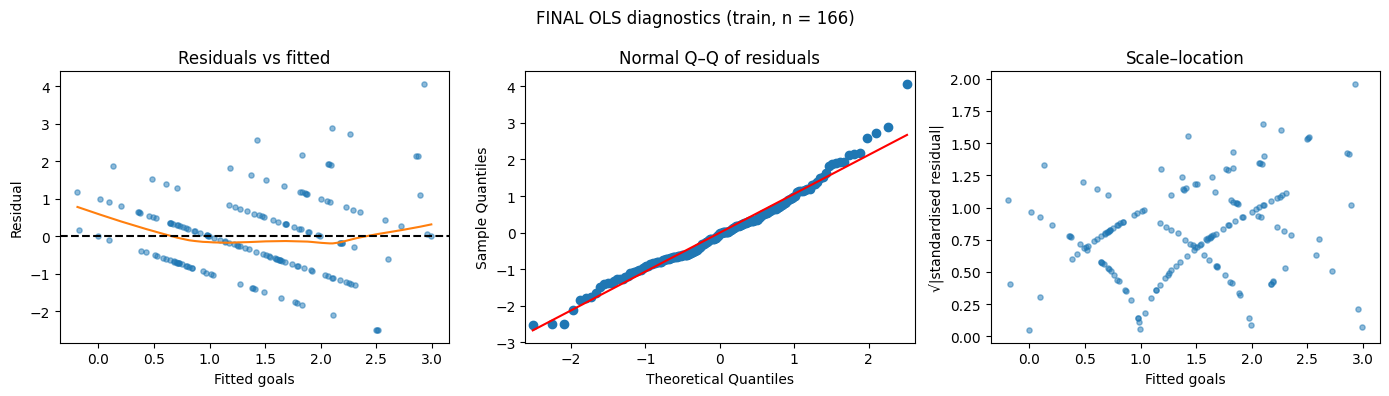

Breusch–Pagan p = 0.0001


In [131]:
from statsmodels.stats.diagnostic import het_breuschpagan
import statsmodels.api as smapi

fit = smapi.OLS(train["goals_90"], smapi.add_constant(train[FINAL])).fit()
res, fv = fit.resid, fit.fittedvalues

fig, ax = plt.subplots(1, 3, figsize=(14, 4))
ax[0].scatter(fv, res, s=14, alpha=.5); sm_ = lowess(res, fv, frac=.6); ax[0].plot(sm_[:, 0], sm_[:, 1], "C1")
ax[0].axhline(0, c="k", ls="--"); ax[0].set(xlabel="Fitted goals", ylabel="Residual", title="Residuals vs fitted")
smapi.qqplot(res, line="s", ax=ax[1]); ax[1].set_title("Normal Q–Q of residuals")
ax[2].scatter(fv, np.sqrt(np.abs(fit.get_influence().resid_studentized_internal)), s=14, alpha=.5)
ax[2].set(xlabel="Fitted goals", ylabel="√|standardised residual|", title="Scale–location")
fig.suptitle("FINAL OLS diagnostics (train, n = 166)"); plt.tight_layout(); plt.show()

print("Breusch–Pagan p =", round(het_breuschpagan(res, fit.model.exog)[1], 4))

Diagonal striping reflects the discrete goal counts. Residuals show a mild U-shape (under-prediction near zero and at high fitted values, consistent with a count floor and multiplicative effects) and a right-skewed Q–Q tail. Breusch–Pagan confirmed heteroscedasticity (p = 0.0001), so cluster-robust standard errors were used.

In [132]:
y, X = train["goals_90"], smapi.add_constant(train[FINAL])
g_match = pd.factorize(train["match_no"])[0]        # factorize: labels → integer codes (statsmodels needs ints)
g_team  = pd.factorize(train["team"])[0]
ols = smapi.OLS(y, X)
fits = {
    "classical":     ols.fit(),
    "HC3":           ols.fit(cov_type="HC3"),                                   # heteroscedasticity-robust only
    "cluster match": ols.fit(cov_type="cluster", cov_kwds={"groups": g_match}),
    "cluster team":  ols.fit(cov_type="cluster", cov_kwds={"groups": g_team}),
    "two-way":       ols.fit(cov_type="cluster", cov_kwds={"groups": np.column_stack([g_match, g_team])}),
}
print("coef:\n", fits["classical"].params.round(3))
print("\nSE:\n",  pd.DataFrame({k: f.bse for k, f in fits.items()}).round(3))
print("\np:\n",   pd.DataFrame({k: f.pvalues for k, f in fits.items()}).round(3))
print("\nclusters: match", g_match.max() + 1, "| team", g_team.max() + 1)

coef:
 const       0.851
lsv_diff    0.383
age_diff    0.183
att_est     0.483
knockout   -0.327
dtype: float64

SE:
           classical    HC3  cluster match  cluster team  two-way
const         0.243  0.219          0.228         0.210    0.224
lsv_diff      0.052  0.060          0.051         0.052    0.043
age_diff      0.060  0.057          0.048         0.060    0.052
att_est       0.169  0.155          0.156         0.128    0.133
knockout      0.184  0.170          0.176         0.158    0.168

p:
           classical    HC3  cluster match  cluster team  two-way
const         0.001  0.000          0.000         0.000    0.000
lsv_diff      0.000  0.000          0.000         0.000    0.000
age_diff      0.003  0.001          0.000         0.002    0.000
att_est       0.005  0.002          0.002         0.000    0.000
knockout      0.077  0.054          0.063         0.039    0.051

clusters: match 83 | team 48


In [133]:
# Cook's distance
infl = fit.get_influence()
cd = pd.Series(infl.cooks_distance[0], index=train.index)        # cooks_distance returns (D, p-values); [0] = D
top = cd.sort_values(ascending=False).head(5)
print(train.loc[top.index, ["match_no", "team", "goals_90"] + FINAL].assign(cooks_d=top.round(3)))
print("rows above 4/n:", (cd > 4 / len(cd)).sum())

drop = cd.idxmax()                                               # refit without the most influential row
f2 = smapi.OLS(y.drop(drop), X.drop(drop)).fit()
print(pd.DataFrame({"all": fit.params, "minus top row": f2.params}).round(3))

    match_no         team  goals_90  lsv_diff  age_diff   att_est  knockout  \
19        10      Germany         7  3.603894  0.025799  1.435837         0   
27        14        Spain         0  3.110698 -2.928974  2.088490         0   
76        39      Belgium         0  2.894215 -2.718054  2.153755         0   
67        34      Ecuador         0  2.660578 -1.943348  0.522122         0   
68        35  Netherlands         5  0.619120  0.217343  2.023224         0   

    cooks_d  
19    0.119  
27    0.054  
76    0.051  
67    0.033  
68    0.033  
rows above 4/n: 12
            all  minus top row
const     0.851          0.805
lsv_diff  0.383          0.347
age_diff  0.183          0.170
att_est   0.483          0.490
knockout -0.327         -0.292


## Walk forward validation

In [134]:
bins = [0, 24, 48, 72, 88, 96, 104]                         # schedule blocks (verified below for group stage)
wf_df = train.assign(block=pd.cut(train["match_no"], bins, labels=False) + 1)   # pd.cut: bins match_no → block 1..6
grp = wf_df[wf_df["block"] <= 3]
assert (grp["block"] == grp["team_match_no"]).all()         # if this fails, my schedule mapping is wrong → tell me

models = {"B0": FULL17, "B1": SEL8, "FINAL": FINAL}   # replace B1/B2 with your baseline feature-list variables
rows, sse = [], {m: [0.0, 0] for m in models}
for b in [3, 4, 5, 6]:                                      # predict each block from all earlier blocks only
    tr, va = wf_df[wf_df.block < b], wf_df[wf_df.block == b]
    for name, feats in models.items():
        pred = (np.full(len(va), tr.goals_90.mean()) if feats is None
                else LinearRegression().fit(tr[feats], tr.goals_90).predict(va[feats]))
        e2 = ((va.goals_90 - pred) ** 2).sum()
        sse[name][0] += e2; sse[name][1] += len(va)
        rows.append((b, len(tr), len(va), name, np.sqrt(e2 / len(va))))

wf = pd.DataFrame(rows, columns=["block", "n_train", "n_val", "model", "rmse"])
print(wf.pivot(index=["block", "n_train", "n_val"], columns="model", values="rmse").round(3))
print("\npooled RMSE:", {m: round(np.sqrt(s / n), 3) for m, (s, n) in sse.items()})

model                   B0     B1  FINAL
block n_train n_val                     
3     76      38     1.161  1.093  1.105
4     114     26     0.875  0.753  0.775
5     140     12     1.456  1.323  1.259
6     152     14     1.099  1.007  0.877

pooled RMSE: {'B0': np.float64(1.123), 'B1': np.float64(1.029), 'FINAL': np.float64(1.01)}


An expanding-window walk-forward evaluation (train on earlier rounds, predict the next) preserved FINAL’s skill relative to the mean baseline (RMSE ratio 0.899 vs 0.896 under grouped CV), indicating the CV estimate is not inflated by ignoring time order. FINAL was marginally worse only on the first knockout round, where the stage effect could not yet be estimated.

## Test set

In [135]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

y_test = test["goals_90"].to_numpy()
ybar = train["goals_90"].mean()
specs = {"OLS": (LinearRegression(), FINAL), "Poisson": (pois, FINAL),
         "Ridge": (ridge, FINAL), "Lasso": (lasso, FINAL)}

rows = []
for k, (mdl, f) in specs.items():
    pr = mdl.fit(train[f], train["goals_90"]).predict(test[f])
    rows.append([k, np.sqrt(mean_squared_error(y_test, pr)), mean_absolute_error(y_test, pr),
                 1 - ((y_test - pr) ** 2).sum() / ((y_test - ybar) ** 2).sum(),   # R² vs train mean (out-of-sample)
                 (pr < 0).sum()])
print(pd.DataFrame(rows, columns=["model", "RMSE", "MAE", "R²_oos", "neg preds"]).round(3).to_string(index=False))

  model  RMSE   MAE  R²_oos  neg preds
    OLS 1.521 1.187   0.225          2
Poisson 1.561 1.215   0.184          0
  Ridge 1.519 1.183   0.227          1
  Lasso 1.519 1.185   0.227          2


In [136]:
print("train var", round(train.goals_90.var(), 3), "| test var", round(test.goals_90.var(), 3),
      "| test mean", round(test.goals_90.mean(), 3))
print("B0 test RMSE:", round(np.sqrt(((y_test - ybar) ** 2).mean()), 3))
pr = LinearRegression().fit(train[FINAL], train.goals_90).predict(test[FINAL])
print(test.assign(pred=pr.round(2), err=(y_test - pr).round(2))
      .loc[lambda d: d.err.abs().sort_values(ascending=False).index[:6], ["match_no", "team", "goals_90", "pred", "err"]])

train var 1.649 | test var 3.031 | test mean 1.571
B0 test RMSE: 1.728
     match_no      team  goals_90  pred   err
204       103   England         6  1.45  4.55
52         27    Canada         6  1.84  4.16
205       103    France         4  1.30  2.70
92         47  Portugal         5  2.56  2.44
11          6   Türkiye         0  2.39 -2.39
120        61    France         4  2.01  1.99


In [137]:
keep = test["match_no"] != 103
print("excl. 3rd-place: RMSE", round(np.sqrt(((y_test[keep] - pr[keep]) ** 2).mean()), 3),
      "| B0", round(np.sqrt(((y_test[keep] - ybar) ** 2).mean()), 3),
      "| R²_oos", round(1 - ((y_test[keep] - pr[keep]) ** 2).sum() / ((y_test[keep] - ybar) ** 2).sum(), 3))

excl. 3rd-place: RMSE 1.315 | B0 1.562 | R²_oos 0.292


In [138]:
t = test.assign(pred=pr)
w = t.groupby("match_no").filter(lambda g: g.goals_90.nunique() == 2)             # drop draws: no winner to pick
hit = w.groupby("match_no").apply(lambda g: g.pred.idxmax() == g.goals_90.idxmax())
print(f"picked the higher scorer in {hit.sum()}/{len(hit)} matches ({hit.mean():.0%}) vs 50% coin")
from scipy.stats import binomtest; print("binomial p:", round(binomtest(hit.sum(), len(hit), 0.5, alternative="greater").pvalue, 3))

picked the higher scorer in 13/16 matches (81%) vs 50% coin
binomial p: 0.011


/tmp/ipykernel_3559/1228254324.py:3: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  hit = w.groupby("match_no").apply(lambda g: g.pred.idxmax() == g.goals_90.idxmax())


TEST: n = 42 rows, 21 matches
  model  RMSE   MAE  R²_oos      RMSE CI         R² CI  ΔRMSE vs OLS            Δ CI
    OLS 1.521 1.187   0.225 [1.07, 1.95]  [0.00, 0.45]         0.000  [0.000, 0.000]
Poisson 1.561 1.215   0.184 [1.10, 2.01] [-0.02, 0.41]         0.041 [-0.034, 0.119]
  Ridge 1.519 1.183   0.227 [1.07, 1.95]  [0.02, 0.45]        -0.002 [-0.013, 0.010]
  Lasso 1.519 1.185   0.227 [1.07, 1.95]  [0.01, 0.45]        -0.002 [-0.006, 0.002]


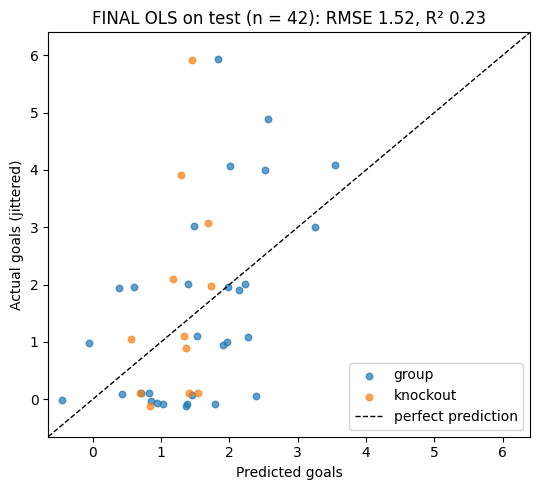

In [139]:
rng = np.random.default_rng(0)
ybar = train["goals_90"].mean()

def scores(y, p):
    return (np.sqrt(np.mean((y - p) ** 2)), np.mean(np.abs(y - p)),
            1 - np.sum((y - p) ** 2) / np.sum((y - ybar) ** 2))

specs = {"OLS": (LinearRegression(), FINAL), "Poisson": (pois, FINAL),
         "Ridge": (ridge, FINAL), "Lasso": (lasso, FINAL)}
preds = {k: mdl.fit(train[f], train["goals_90"]).predict(test[f]) for k, (mdl, f) in specs.items()}
y, p = test["goals_90"].to_numpy(), preds["OLS"]
rmse, mae, r2 = scores(y, p)

mid = test["match_no"].to_numpy()
groups = [np.where(mid == g)[0] for g in np.unique(mid)]                     # row indices per match
samples = [np.concatenate([groups[j] for j in rng.integers(0, len(groups), len(groups))]) for _ in range(5000)]
boot = {k: np.array([scores(y[i], pr[i]) for i in samples]) for k, pr in preds.items()}   # same resamples → paired

rows = []
for k, pr in preds.items():
    s, ci = scores(y, pr), np.percentile(boot[k], [2.5, 97.5], axis=0)
    d = boot[k][:, 0] - boot["OLS"][:, 0]
    rows.append([k, *np.round(s, 3), f"[{ci[0,0]:.2f}, {ci[1,0]:.2f}]", f"[{ci[0,2]:.2f}, {ci[1,2]:.2f}]",
                 round(s[0] - rmse, 3), f"[{np.percentile(d, 2.5):.3f}, {np.percentile(d, 97.5):.3f}]"])
print(f"TEST: n = {len(y)} rows, {len(groups)} matches")
print(pd.DataFrame(rows, columns=["model", "RMSE", "MAE", "R²_oos", "RMSE CI", "R² CI",
                                  "ΔRMSE vs OLS", "Δ CI"]).to_string(index=False))

jit = rng.uniform(-0.12, 0.12, len(y))
ko = test["knockout"].to_numpy() == 1
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(p[~ko], y[~ko] + jit[~ko], s=22, alpha=.7, label="group")
ax.scatter(p[ko], y[ko] + jit[ko], s=22, alpha=.7, label="knockout")
lim = [min(p.min(), 0) - .2, max(y.max(), p.max()) + .4]
ax.plot(lim, lim, "k--", lw=1, label="perfect prediction")
ax.set(xlim=lim, ylim=lim, xlabel="Predicted goals", ylabel="Actual goals (jittered)",
       title=f"FINAL OLS on test (n = {len(y)}): RMSE {rmse:.2f}, R² {r2:.2f}")
ax.legend(); plt.tight_layout(); plt.show()

In [140]:
m = LinearRegression().fit(train[FINAL], train["goals_90"])
t = test.assign(pred=m.predict(test[FINAL]))
err = (t["goals_90"] - t["pred"]).abs().groupby(t["match_no"]).sum()        # total abs error per match

for label, mn in [("closest prediction", err.idxmin()), ("biggest miss", err.idxmax())]:
    g = t[t["match_no"] == mn]
    out = (g[FINAL] * m.coef_).round(2)                                       # each feature's contribution in goals
    out.insert(0, "base", round(m.intercept_, 2))
    out.insert(0, "team", g["team"].values)
    out["predicted"] = g["pred"].round(2); out["actual"] = g["goals_90"]
    print(f"\nMatch {mn} — {label}"); print(out.to_string(index=False))


Match 42 — closest prediction
  team  base  lsv_diff  age_diff  att_est  knockout  predicted  actual
France  0.85      1.64      0.02     0.76      -0.0       3.26       3
  Iraq  0.85     -1.64     -0.02     0.35      -0.0      -0.45       0

Match 103 — biggest miss
   team  base  lsv_diff  age_diff  att_est  knockout  predicted  actual
England  0.85     -0.04      0.03     0.95     -0.33       1.45       6
 France  0.85      0.04     -0.03     0.76     -0.33       1.30       4


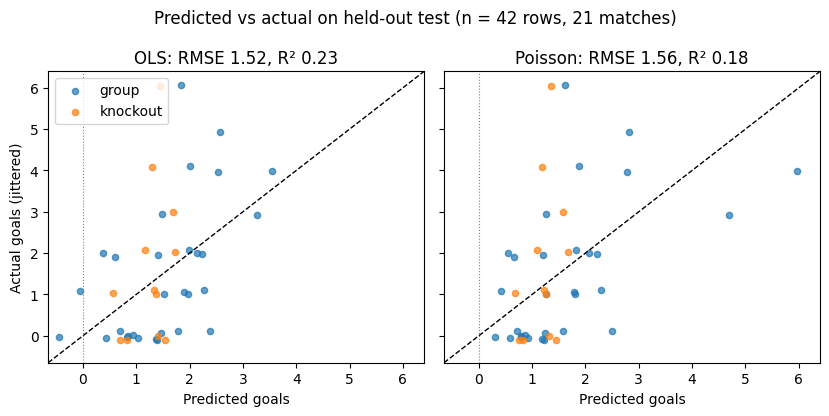

In [141]:
show = ["OLS", "Poisson"]
ko = test["knockout"].to_numpy() == 1
jit = np.random.default_rng(1).uniform(-0.12, 0.12, len(y))   # same jitter in every panel, so points line up across panels
lim = [min(min(preds[m].min() for m in show), 0) - .2, max(y.max(), max(preds[m].max() for m in show)) + .4]

fig, axes = plt.subplots(1, len(show), figsize=(4.2 * len(show), 4.2), sharex=True, sharey=True)  # sharex/sharey: identical axes → panels directly comparable
for ax, m in zip(axes, show):
    p_m = preds[m]
    ax.scatter(p_m[~ko], y[~ko] + jit[~ko], s=20, alpha=.7, label="group")
    ax.scatter(p_m[ko],  y[ko] + jit[ko],  s=20, alpha=.7, label="knockout")
    ax.plot(lim, lim, "k--", lw=1)
    ax.axvline(0, color="grey", lw=.8, ls=":")       # makes negative predictions visible at a glance
    r, _, r2_m = scores(y, p_m)
    ax.set(title=f"{m}: RMSE {r:.2f}, R² {r2_m:.2f}", xlabel="Predicted goals", xlim=lim, ylim=lim)
axes[0].set_ylabel("Actual goals (jittered)"); axes[0].legend(loc="upper left")
fig.suptitle(f"Predicted vs actual on held-out test (n = {len(y)} rows, 21 matches)")
plt.tight_layout(); plt.show()

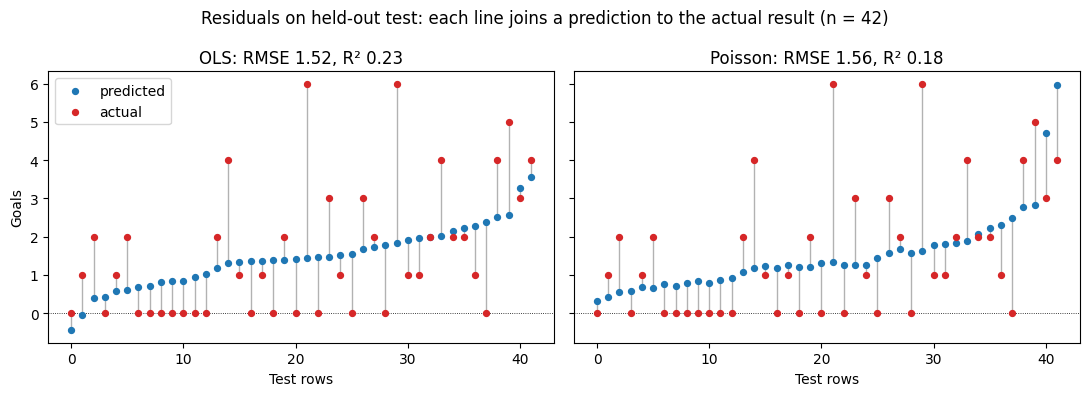

In [143]:
order_idx = np.argsort(preds["OLS"])                      # sort rows by OLS prediction; same order in both panels → same row = same x
x = np.arange(len(y))
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, m in zip(axes, ["OLS", "Poisson"]):
    p_m, y_s = preds[m][order_idx], y[order_idx]
    ax.vlines(x, p_m, y_s, color="grey", lw=1, alpha=.6)  # vlines(x, ymin, ymax): one vertical segment per row = the residual
    ax.scatter(x, p_m, s=18, color="C0", label="predicted", zorder=3)   # zorder: draw dots on top of the lines
    ax.scatter(x, y_s, s=18, color="C3", label="actual", zorder=3)
    ax.axhline(0, color="black", lw=.6, ls=":")           # shows predictions below zero
    r, _, r2_m = scores(y, preds[m])
    ax.set(title=f"{m}: RMSE {r:.2f}, R² {r2_m:.2f}", xlabel="Test rows")
axes[0].set_ylabel("Goals"); axes[0].legend(loc="upper left")
fig.suptitle(f"Residuals on held-out test: each line joins a prediction to the actual result (n = {len(y)})")
plt.tight_layout(); plt.show()

## Coefficient Comparison

In [146]:
X, yt = smapi.add_constant(train[FINAL]), train["goals_90"]
fits = {c: smapi.OLS(yt, X).fit(cov_type="cluster", cov_kwds={"groups": pd.factorize(train[c])[0]})
        for c in ["match_no", "team"]}            # factorize: turns labels into integer codes, which clustering needs

b = fits["match_no"].params                      # coefficients are the same under either clustering; only SEs differ
tab = pd.DataFrame({"coef": b})
for c, f in fits.items():
    ci = f.conf_int()
    tab[f"CI ({c})"] = [f"[{lo:.3f}, {hi:.3f}]" for lo, hi in zip(ci[0], ci[1])]
    tab[f"p ({c})"] = f.pvalues.round(4)
sd = train[FINAL].std()
tab["SD"] = sd
tab["per 2 SD"] = [b[f] * (1 if f == "knockout" else 2 * sd[f]) for f in FINAL] + [np.nan] if False else \
                  pd.Series({f: b[f] * (1 if f == "knockout" else 2 * sd[f]) for f in FINAL})
print(tab.round(3).to_string())

           coef    CI (match_no)  p (match_no)         CI (team)  p (team)     SD  per 2 SD
const     0.851   [0.404, 1.299]         0.000    [0.440, 1.263]     0.000    NaN       NaN
lsv_diff  0.383   [0.282, 0.483]         0.000    [0.280, 0.485]     0.000  1.716     1.313
age_diff  0.183   [0.089, 0.276]         0.000    [0.066, 0.300]     0.002  1.507     0.550
att_est   0.483   [0.178, 0.788]         0.002    [0.233, 0.733]     0.000  0.528     0.510
knockout -0.327  [-0.673, 0.018]         0.063  [-0.638, -0.017]     0.039  0.465    -0.327


squad-value gap, squad age gap and pre-tournament attack all predict goals robustly under both clusterings (p ≤ 0.002), with value the largest (+1.31 goals per 2 SD). Knockout stage (−0.33 goals) is suggestive only (p = 0.063 by match, 0.039 by team).

## Interpretation

In [148]:
coef, mu = fits["match_no"].params, train[FINAL].mean()
te = test.assign(pred=preds["OLS"], pois=preds["Poisson"], err=y - preds["OLS"])
contrib = (te[FINAL] - mu) * coef[FINAL]                 # each feature's push away from the average team
te = te.join(contrib.add_prefix("c_"))
base = ybar                                              # OLS with intercept: average prediction on train = train mean


picks = {"accurate favourite": te.loc[te.pred > 2, "err"].abs().idxmin(),
         "biggest upset": te["err"].idxmin(),             # most negative error = scored far below prediction
         "Poisson overshoot": te["pois"].idxmax()}
cols = ["team", "goals_90", "pred", "pois"] + ["c_" + f for f in FINAL]
for label, i in picks.items():
    print(f"\n{label} — match {te.loc[i, 'match_no']} (base {base:.2f})")
    print(te.loc[te.match_no == te.loc[i, "match_no"], cols].round(2).to_string(index=False))


accurate favourite — match 1 (base 1.41)
        team  goals_90  pred  pois  c_lsv_diff  c_age_diff  c_att_est  c_knockout
      Mexico         2  2.14  2.07        0.52         0.2      -0.09         0.1
South Africa         0  0.70  0.71       -0.52        -0.2      -0.09         0.1

biggest upset — match 6 (base 1.41)
     team  goals_90  pred  pois  c_lsv_diff  c_age_diff  c_att_est  c_knockout
Australia         2  0.61  0.66       -0.69       -0.06      -0.16         0.1
  Türkiye         0  2.39  2.49        0.69        0.06       0.13         0.1

Poisson overshoot — match 18 (base 1.41)
  team  goals_90  pred  pois  c_lsv_diff  c_age_diff  c_att_est  c_knockout
  Iraq         1 -0.05  0.41       -1.27        0.02      -0.31         0.1
Norway         4  3.55  5.96        1.27       -0.02       0.79         0.1
